<a href="https://colab.research.google.com/github/11465005-tech/ChineseEmoBank_ValenceArousal/blob/main/chinese_pipelined_bert_pipeline_v7_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 中文版 Pipelined Neural Networks v7-2 — BERT 遞迴 Pipeline（修正版）
## v7-2 針對 v7 的四個改進
1. 修飾詞語境化：`BERT(modifier [SEP] target_text)`，不再只看孤立副詞。
2. 片語切割強化：由右向左找核心詞，並切出修飾詞鏈（modifier chain）。
3. `c_mod` 雙軸化：同時輸出 `Cmod-V` / `Cmod-A` 並視覺化分布。
4. V/A 互動建模：NNmod 加入 `[v, a, v*a, v-a]` 互動特徵。
## 架構設計（兩階段 Pipeline 保持不變）
```
Stage 1: BERT(word) -> NNword -> Int(w)
Stage 2: BERT(core) -> NNword(frozen) -> Int(w)
         BERT(modifier [SEP] core/phrase) -> NNmod -> Int(mod phrase)
```
多修飾詞時維持遞迴：由最靠近核心詞的修飾詞開始逐層往外套用。

## 0. 安裝套件

In [ ]:
# 已安裝好的 Colab 環境可略過；第一次跑或套件版本不對時再打開這行
# !pip install transformers torch pandas numpy scikit-learn scipy matplotlib -q

## 1. 設定執行環境（Colab 版：掛載 Google Drive、偵測 GPU）

In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import kendalltau, spearmanr, pearsonr
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'使用裝置: {device}')

try:
    import subprocess, glob
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'fonts-noto-cjk'],
                    check=True, capture_output=True, text=True)
    subprocess.run(['fc-cache', '-f'], capture_output=True)

    import matplotlib.font_manager as fm
    # apt 裝好字型檔之後，matplotlib 這個 process 裡的字型快取不會自動更新，
    # 一定要用 addfont() 手動註冊剛裝好的字型檔，否則畫圖時還是找不到、
    # 悄悄退回沒有中文字的預設字型（之前中文變方塊的原因）。
    for fp in glob.glob('/usr/share/fonts/**/*CJK*', recursive=True):
        try:
            fm.fontManager.addfont(fp)
        except Exception:
            pass

    cjk_candidates = ['Noto Sans CJK TC', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
    available = {f.name for f in fm.fontManager.ttflist}
    cjk_font = next((c for c in cjk_candidates if c in available), None)
    if cjk_font is None:
        cjk_font = next((f.name for f in fm.fontManager.ttflist if 'CJK' in f.name), None)

    if cjk_font:
        plt.rcParams['font.sans-serif'] = [cjk_font]
        plt.rcParams['font.family'] = 'sans-serif'
        plt.rcParams['axes.unicode_minus'] = False
        print(f'[字型] 已安裝並套用中文字型: {cjk_font}')
    else:
        print('[字型] \u26a0 套件裝好了，但沒偵測到 CJK 字型名稱，圖中中文可能還是方塊——'
              '「執行階段 > 重新啟動工作階段」後再重跑全部通常能解決。')
except Exception as e:
    print(f'[字型] \u26a0 安裝中文字型失敗：{e}')
    print('  可以在上面另開一格手動執行：!apt-get install -y fonts-noto-cjk && fc-cache -f')
    print('  裝完後「執行階段 > 重新啟動工作階段」，再重跑全部 cell')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
使用裝置: cuda
[字型] 已安裝並套用中文字型: Noto Sans CJK JP


## 路徑設定（Colab 版：Google Drive 路徑，需要的話自行修改）

In [ ]:
BASE     = '/content/drive/MyDrive/研究/dimABSA/DataSets/ChineseEmoBank'
SAVE_DIR = '/content/drive/MyDrive/研究/dimABSA/models'
BERT_NAME = 'hfl/chinese-bert-wwm-ext'

import os; os.makedirs(SAVE_DIR, exist_ok=True)

## 資料載入（Colab 版：從 Google Drive 讀取 CSV）

In [ ]:
def read_csv_robust(path, sep='\t', _retried=False):
    # Google Drive 在 Colab 是用 FUSE 掛載的，長時間跑、或連續讀好幾個檔案時
    # 偶爾會斷線（OSError: [Errno 107] Transport endpoint is not connected）——
    # 這是 Drive 掛載點本身失聯，不是檔案壞掉，重新掛載一次通常就會好。
    for enc in ['utf-8', 'utf-8-sig', 'big5', 'gb18030', 'cp950']:
        try:
            df = pd.read_csv(path, sep=sep, encoding=enc)
            print(f'  -> {path.split("/")[-1]} 使用編碼: {enc}')
            return df
        except (UnicodeDecodeError, UnicodeError):
            continue
        except OSError as e:
            if _retried:
                raise
            print(f'  \u26a0 讀取 {path.split("/")[-1]} 時 Google Drive 連線中斷（{e}），'
                  f'重新掛載 Drive 後重試一次...')
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            return read_csv_robust(path, sep=sep, _retried=True)
    return pd.read_csv(path, sep=sep, encoding='utf-8', encoding_errors='replace')

cvaw = read_csv_robust(f'{BASE}/CVAW_SD/CVAW_all_SD.csv')
cvap = read_csv_robust(f'{BASE}/CVAP_SD/CVAP_all_SD.csv')
cvas = read_csv_robust(f'{BASE}/CVAS_SD/CVAS_all.csv')
print(f'CVAW: {len(cvaw)}  CVAP: {len(cvap)}  CVAS: {len(cvas)}')

  -> CVAW_all_SD.csv 使用編碼: utf-8
  -> CVAP_all_SD.csv 使用編碼: utf-8
  -> CVAS_all.csv 使用編碼: utf-8
CVAW: 5512  CVAP: 2250  CVAS: 2583


## [新增] CVAW 詞典 Valence-Arousal 散佈圖（仿論文 Fig. 3 樣式）

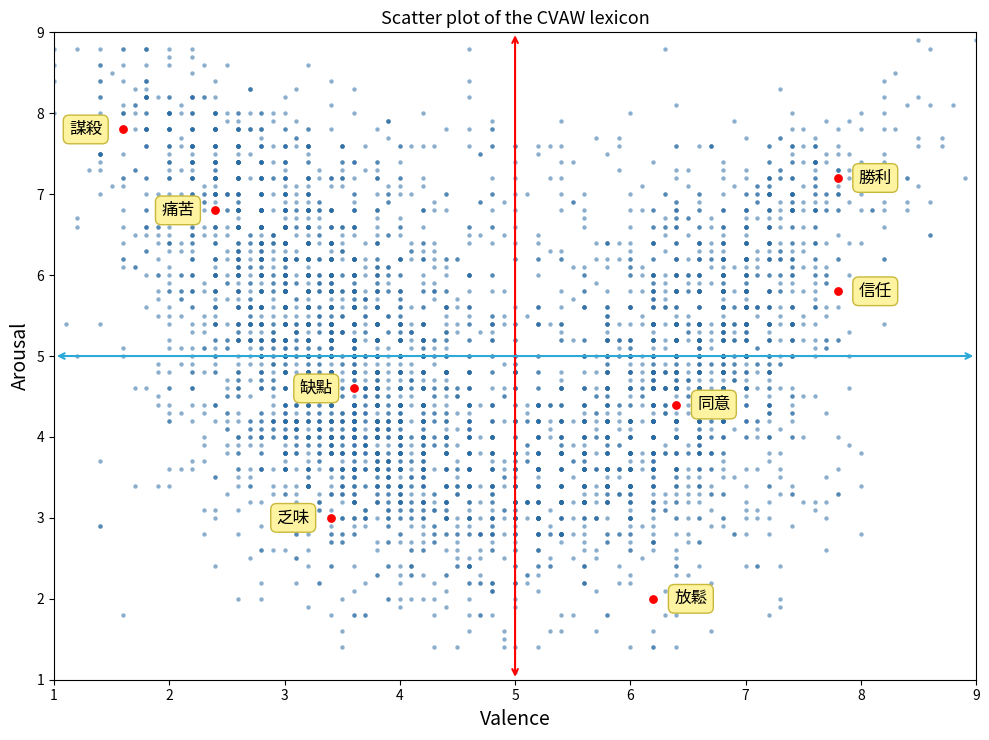

已標註的詞: {'乏味', '信任', '缺點', '謀殺', '放鬆', '同意', '痛苦', '勝利'}


In [ ]:
LABEL_WORDS = [
    ('謀殺', (-15, 0),  (1.6, 8.0)),   # 左上：高激發、負向
    ('痛苦', (-15, 0),  (2.0, 6.8)),
    ('勝利', (15, 0),   (7.8, 7.0)),   # 右上：高激發、正向
    ('信任', (15, 0),   (7.8, 5.7)),
    ('缺點', (-15, 0),  (3.6, 4.5)),   # 中間偏負
    ('同意', (15, 0),   (6.4, 4.3)),   # 中間偏正
    ('乏味', (-15, 0),  (2.5, 3.0)),   # 左下：低激發、負向
    ('放鬆', (15, 0),   (6.3, 2.0)),   # 右下：低激發、正向
]


def _nearest_word(df, target_v, target_a, exclude=set()):
    d = (df['Valence_Mean'] - target_v) ** 2 + (df['Arousal_Mean'] - target_a) ** 2
    d[df['Word'].isin(exclude)] = np.inf
    idx = d.idxmin()
    return df.loc[idx, 'Word'], df.loc[idx, 'Valence_Mean'], df.loc[idx, 'Arousal_Mean']


def plot_cvaw_scatter(df):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(df['Valence_Mean'], df['Arousal_Mean'],
               s=10, color='#2b6ca3', alpha=0.55, linewidths=0, zorder=2)
    ax.annotate('', xy=(5, 9), xytext=(5, 1),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5), zorder=3)
    ax.annotate('', xy=(9, 5), xytext=(1, 5),
                arrowprops=dict(arrowstyle='<->', color='#2ca9d6', lw=1.5), zorder=3)

    used_words = set()
    for word, offset, fallback_xy in LABEL_WORDS:
        row = df[df['Word'] == word]
        if len(row):
            v, a = row.iloc[0]['Valence_Mean'], row.iloc[0]['Arousal_Mean']
            label = word
        else:
            label, v, a = _nearest_word(df, *fallback_xy, exclude=used_words)
        used_words.add(label)
        ax.scatter([v], [a], s=28, color='red', zorder=4)
        ax.annotate(label, xy=(v, a), xytext=offset, textcoords='offset points',
                    fontsize=12, va='center',
                    ha='right' if offset[0] < 0 else 'left',
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdf3a0',
                              edgecolor='#c9b93a', linewidth=1),
                    zorder=5)

    ax.set_xlim(1, 9); ax.set_ylim(1, 9)
    ax.set_xlabel('Valence', fontsize=14)
    ax.set_ylabel('Arousal', fontsize=14)
    ax.set_title('Scatter plot of the CVAW lexicon', fontsize=13)
    plt.tight_layout()
    plt.savefig('cvaw_scatter.png', dpi=200)
    plt.show()
    print('已標註的詞:', used_words)


plot_cvaw_scatter(cvaw)

## [新增] 通用版 VA 散佈圖工具（給 NNword / NNmod / NNsent 預測結果用）

In [ ]:
VA_SCATTER_ANCHORS = [
    ((-15, 0), (1.6, 8.0)),
    ((-15, 0), (2.0, 6.8)),
    ((15, 0),  (7.8, 7.0)),
    ((15, 0),  (7.8, 5.7)),
    ((-15, 0), (3.6, 4.5)),
    ((15, 0),  (6.4, 4.3)),
    ((-15, 0), (2.5, 3.0)),
    ((15, 0),  (6.3, 2.0)),
]


def _nearest_item(vs, as_, texts, target_v, target_a, exclude):
    d = (vs - target_v) ** 2 + (as_ - target_a) ** 2
    d = d.copy()
    for i in exclude:
        d[i] = np.inf
    idx = int(np.argmin(d))
    return idx, vs[idx], as_[idx], texts[idx]


def plot_va_scatter(values_v, values_a, texts, title, savepath=None, max_len=10):
    """
    values_v / values_a：模型輸出的正規化 [0,1] VA 陣列，自動還原成 1-9 分數畫圖。
    texts：對應每個點的原文字（詞／短語／句子），自動挑離八個象限錨點最近的
           實際樣本標註，不用手動指定詞表。
    """
    vs = np.asarray(values_v, dtype=np.float64) * 8 + 1
    as_ = np.asarray(values_a, dtype=np.float64) * 8 + 1
    texts = list(texts)

    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(vs, as_, s=10, color='#2b6ca3', alpha=0.45, linewidths=0, zorder=2)
    ax.annotate('', xy=(5, 9), xytext=(5, 1),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5), zorder=3)
    ax.annotate('', xy=(9, 5), xytext=(1, 5),
                arrowprops=dict(arrowstyle='<->', color='#2ca9d6', lw=1.5), zorder=3)

    used = set()
    for offset, (tv, ta) in VA_SCATTER_ANCHORS:
        idx, v, a, txt = _nearest_item(vs, as_, texts, tv, ta, used)
        used.add(idx)
        label = txt if len(txt) <= max_len else txt[:max_len] + '…'
        ax.scatter([v], [a], s=28, color='red', zorder=4)
        ax.annotate(label, xy=(v, a), xytext=offset, textcoords='offset points',
                    fontsize=11, va='center',
                    ha='right' if offset[0] < 0 else 'left',
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdf3a0',
                              edgecolor='#c9b93a', linewidth=1),
                    zorder=5)

    ax.set_xlim(1, 9); ax.set_ylim(1, 9)
    ax.set_xlabel('Valence', fontsize=14)
    ax.set_ylabel('Arousal', fontsize=14)
    ax.set_title(title, fontsize=13)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
    plt.show()


print('plot_va_scatter 定義完成（NNword / NNmod / NNsent 共用）')

plot_va_scatter 定義完成（NNword / NNmod / NNsent 共用）


## 2. 資料前處理
v7-2 進一步加入否定詞範圍規則（例如「不是很」「並不太」），
提升複合修飾詞切割的穩定性，減少誤切。

In [ ]:
def normalize_va(df, val_col='Valence_Mean', aro_col='Arousal_Mean'):
    df = df.copy()
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
    df[aro_col] = pd.to_numeric(df[aro_col], errors='coerce')
    before = len(df)
    df = df.dropna(subset=[val_col, aro_col]).reset_index(drop=True)
    if before - len(df) > 0:
        print(f'  ⚠ 清除 {before-len(df)} 筆髒資料')
    df['valence'] = (df[val_col] - 1) / 8.0
    df['arousal'] = (df[aro_col] - 1) / 8.0
    return df
cvaw = normalize_va(cvaw)
cvap = normalize_va(cvap)
cvas = normalize_va(cvas)
# CVAP 短語切割：由右向左找核心詞 + 否定詞範圍規則
cvaw_word_set = set(cvaw['Word'].astype(str).tolist())
max_core_len = max(len(w) for w in cvaw_word_set)
# 否定詞與程度詞（長詞優先匹配）
NEGATION_CUES = {
    '不是很', '並不太', '並不是', '不怎麼', '不太', '不是', '並不', '沒有', '沒', '不', '無', '未', '別', '勿'
}
DEGREE_CUES = {
    '超級', '極為', '非常', '相當', '十分', '更加', '格外', '特別', '有點', '稍微', '很', '太', '更', '極', '超'
}
# 常見多詞修飾鏈，優先整體匹配
COMPOSITE_MODIFIERS = {
    '不是很', '並不太', '並不是很', '沒有很', '不怎麼', '不太'
}
MODIFIER_LEXICON = sorted(
    COMPOSITE_MODIFIERS | NEGATION_CUES | DEGREE_CUES,
    key=len,
    reverse=True
)
def normalize_text(s):
    s = str(s).strip()
    for ch in '，。！？、,.!?;；：「」『』（）() ':
        s = s.replace(ch, '')
    return s
def split_modifier_chain(modifier_text):
    """
    規則切分：
    1) 優先匹配複合否定程度詞（如 不是很/並不太）
    2) 次優先匹配一般否定或程度詞
    3) 未知片段退回單字，避免直接丟失資訊
    """
    txt = normalize_text(modifier_text)
    if not txt:
        return []
    mods = []
    i = 0
    while i < len(txt):
        matched = None
        for tok in MODIFIER_LEXICON:
            if txt.startswith(tok, i):
                matched = tok
                break
        if matched is None:
            matched = txt[i:i+1]
        mods.append(matched)
        i += len(matched)
    # 後處理：若出現「不是 + 很」「並不 + 太」再合併回範圍詞
    merged = []
    j = 0
    while j < len(mods):
        if j + 1 < len(mods):
            pair = mods[j] + mods[j + 1]
            if pair in COMPOSITE_MODIFIERS:
                merged.append(pair)
                j += 2
                continue
        merged.append(mods[j])
        j += 1
    return merged
def split_phrase(phrase, cvaw_words):
    phrase = normalize_text(phrase)
    candidates = []
    upper = min(max_core_len, len(phrase) - 1)
    for core_len in range(upper, 0, -1):
        core = phrase[-core_len:]
        modifier = phrase[:-core_len]
        if core in cvaw_words and len(modifier) > 0:
            mod_tokens = split_modifier_chain(modifier)
            neg_hits = sum(t in NEGATION_CUES for t in mod_tokens)
            deg_hits = sum(t in DEGREE_CUES for t in mod_tokens)
            # 先偏好含關鍵修飾詞，再偏好較長核心詞
            score = (neg_hits + deg_hits, neg_hits, core_len)
            candidates.append((score, modifier, core, mod_tokens))
    if candidates:
        _, modifier, core, mod_tokens = max(candidates, key=lambda x: x[0])
        return modifier, core, mod_tokens
    return None, None, []
mods, cores, mod_chains = [], [], []
for phrase in cvap['Phrase']:
    m, c, chain = split_phrase(phrase, cvaw_word_set)
    mods.append(m)
    cores.append(c)
    mod_chains.append(chain)
cvap['modifier'] = mods
cvap['core_word'] = cores
cvap['modifier_chain'] = mod_chains
cvap_aligned = cvap.dropna(subset=['modifier', 'core_word']).copy()
print(f'CVAP 對齊: {len(cvap_aligned)} / {len(cvap)} 筆')
print('切割示例（前 5 筆）:')
print(cvap_aligned[['Phrase', 'modifier', 'core_word', 'modifier_chain']].head().to_string(index=False))
# 8:2 切分
cvaw_train, cvaw_test = train_test_split(cvaw,         test_size=0.2, random_state=42)
cvap_train, cvap_test = train_test_split(cvap_aligned, test_size=0.2, random_state=42)
print(f'CVAW 訓練:{len(cvaw_train)}  測試:{len(cvaw_test)}')
print(f'CVAP 訓練:{len(cvap_train)}  測試:{len(cvap_test)}')

CVAP 對齊: 2249 / 2250 筆
切割示例（前 5 筆）:
Phrase modifier core_word modifier_chain
   怪八卦        怪        八卦            [怪]
  更加小心       更加        小心           [更加]
  格外小心       格外        小心           [格外]
  特別小心       特別        小心           [特別]
  極為小心       極為        小心           [極為]
CVAW 訓練:4409  測試:1103
CVAP 訓練:1799  測試:450


In [ ]:
# 規則切割 sanity check（否定詞範圍）
probe_phrases = [
    '不是很開心',
    '並不太滿意',
    '不怎麼快樂',
    '沒有很失望',
    '非常開心',
]
print('=== Modifier Scope Sanity Check ===')
for p in probe_phrases:
    m, c, chain = split_phrase(p, cvaw_word_set)
    print(f'{p:8s} -> modifier={m}, core={c}, chain={chain}')

=== Modifier Scope Sanity Check ===
不是很開心    -> modifier=不是很, core=開心, chain=['不是很']
並不太滿意    -> modifier=並不太, core=滿意, chain=['並不太']
不怎麼快樂    -> modifier=不怎麼, core=快樂, chain=['不怎麼']
沒有很失望    -> modifier=沒有很, core=失望, chain=['沒有很']
非常開心     -> modifier=非常, core=開心, chain=['非常']


## 3. 載入中文 BERT
v7-2 除了單詞向量，也新增「修飾詞 + 被修飾詞」的 pair 向量：  
`BERT(modifier [SEP] target_text)`，讓 NNmod 具備語境感知能力。

In [ ]:
BERT_NAME = 'hfl/chinese-bert-wwm-ext'
print(f'載入 {BERT_NAME}（約需 1~2 分鐘）...')
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).to(device)
BERT_DIM = bert_model.config.hidden_size
print(f'✅ 載入完成 | hidden size: {BERT_DIM}')
@torch.no_grad()
def get_bert_vec(text):
    """
    單輸入 BERT [CLS]。
    用於核心詞的 base 情緒表示。
    """
    bert_model.eval()
    enc = tokenizer(
        text, return_tensors='pt',
        padding=True, truncation=True, max_length=16
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
@torch.no_grad()
def get_bert_pair_vec(modifier, target_text):
    """
    語境化修飾詞向量：BERT(modifier [SEP] target_text)
    讓 NNmod 感知修飾詞正在修飾哪個詞/片語。
    """
    bert_model.eval()
    enc = tokenizer(
        modifier,
        target_text,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=24
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
# 批次版本（訓練時效率更高）
@torch.no_grad()
def get_bert_vecs_batch(texts, batch_size=64):
    bert_model.eval()
    all_vecs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = tokenizer(
            batch, return_tensors='pt',
            padding=True, truncation=True, max_length=16
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
@torch.no_grad()
def get_bert_pair_vecs_batch(modifiers, targets, batch_size=64):
    bert_model.eval()
    all_vecs = []
    n = len(modifiers)
    for i in range(0, n, batch_size):
        b_mod = modifiers[i:i+batch_size]
        b_tgt = targets[i:i+batch_size]
        enc = tokenizer(
            b_mod,
            b_tgt,
            return_tensors='pt',
            padding=True,
            truncation=True,
            max_length=24
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
# 測試
v1 = get_bert_vec('開心')
v2 = get_bert_vec('難過')
pair_v = get_bert_pair_vec('非常', '開心')
sim_happy_sad = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))
print(f'開心 vs 難過 cosine: {sim_happy_sad:.4f}')
print(f'BERT 向量維度: {v1.shape} | pair 向量維度: {pair_v.shape}')

載入 hfl/chinese-bert-wwm-ext（約需 1~2 分鐘）...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: hfl/chinese-bert-wwm-ext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ 載入完成 | hidden size: 768
開心 vs 難過 cosine: 0.8179
BERT 向量維度: (768,) | pair 向量維度: (768,)


## 4. 模型定義
### NNword head：BERT 向量 → VA 值
維持單詞基準情緒估計。
### NNmod：語境化修飾 + V/A 互動
輸入改為 `BERT(modifier [SEP] target_text)`，並加入 `v, a, v*a, v-a` 互動特徵，
讓 Valence/Arousal 的偏移可共享語意表示、降低獨立建模限制。

In [ ]:
class NNword(nn.Module):
    """
    v7-2 版 NNword：BERT [CLS] → Valence / Arousal
    輸入：BERT 768 維向量（單詞）
    輸出：val, aro ∈ [0,1]
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(bert_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )
    def forward(self, bert_vec):
        out = torch.sigmoid(self.net(bert_vec))
        return out[:, 0:1], out[:, 1:2]
class NNmod(nn.Module):
    """
    v7-2 版 NNmod：語境化修飾 + V/A 互動建模
    輸入：
      1) Int_val(w), Int_aro(w)
      2) BERT(modifier [SEP] target_text) 的語境向量
    設計重點：
      - delta 由 shared hidden 同時決定 val/aro（共享表示，允許耦合）
      - 加入 [v, a, v*a, v-a] 互動特徵
      - 回傳 c_mod_v / c_mod_a，便於雙維度分析
      - 使用 LayerNorm 以支援遞迴鏈訓練時的 batch size=1
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        feat_dim = bert_dim + 4
        self.fc1 = nn.Linear(feat_dim, 192)
        self.fc2 = nn.Linear(192, 64)
        self.fc3 = nn.Linear(64, 2)
        self.ln1 = nn.LayerNorm(192)
        self.ln2 = nn.LayerNorm(64)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    def forward(self, int_val, int_aro, bert_mod_ctx):
        va_feat = torch.cat([
            int_val,
            int_aro,
            int_val * int_aro,
            int_val - int_aro
        ], dim=1)
        x = torch.cat([bert_mod_ctx, va_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        delta_v = delta[:, 0:1]
        delta_a = delta[:, 1:2]
        out_v = torch.sigmoid(torch.logit(int_val.clamp(0.01, 0.99)) + delta_v * 3)
        out_a = torch.sigmoid(torch.logit(int_aro.clamp(0.01, 0.99)) + delta_a * 3)
        c_mod_v = delta_v + 0.5
        c_mod_a = delta_a + 0.5
        return out_v, out_a, c_mod_v, c_mod_a
print('NNword / NNmod（v7-2）定義完成')

NNword / NNmod（v7-2）定義完成


## 5. 預先計算所有 BERT 向量（含遞迴鏈）
除了 core word 向量，也快取遞迴鏈每一步需要的 pair context 向量：  
`modifier [SEP] current_phrase`，供 Stage 2 直接訓練多層遞迴鏈。

In [ ]:
print('預先計算 CVAW 訓練集詞向量...')
word_train_vecs = get_bert_vecs_batch(cvaw_train['Word'].tolist())
word_train_val  = cvaw_train['valence'].values.astype(np.float32)
word_train_aro  = cvaw_train['arousal'].values.astype(np.float32)
print('預先計算 CVAW 測試集詞向量...')
word_test_vecs  = get_bert_vecs_batch(cvaw_test['Word'].tolist())
word_test_val   = cvaw_test['valence'].values.astype(np.float32)
word_test_aro   = cvaw_test['arousal'].values.astype(np.float32)
print('建立遞迴鏈訓練樣本（含 context cache）...')
core_cache = {}
pair_cache = {}
def get_core_vec_cached(word):
    if word not in core_cache:
        core_cache[word] = get_bert_vec(word)
    return core_cache[word]
def get_pair_vec_cached(modifier, target):
    key = (modifier, target)
    if key not in pair_cache:
        pair_cache[key] = get_bert_pair_vec(modifier, target)
    return pair_cache[key]
def build_recursive_chain_samples(df):
    samples = []
    for _, row in df.iterrows():
        core = str(row['core_word'])
        chain = row['modifier_chain'] if isinstance(row['modifier_chain'], list) else []
        if len(chain) == 0:
            chain = [str(row['modifier'])]
        cur_phrase = core
        ctx_chain = []
        # 由最靠近核心詞者先作用，因此反向展開
        for mod in reversed(chain):
            mod = str(mod)
            ctx_chain.append(get_pair_vec_cached(mod, cur_phrase))
            cur_phrase = mod + cur_phrase
        samples.append({
            'core_word': core,
            'full_phrase': str(row['Phrase']),
            'mods_outer_to_inner': chain,
            'ctx_chain': ctx_chain,
            'core_vec': get_core_vec_cached(core),
            'valence': float(row['valence']),
            'arousal': float(row['arousal']),
        })
    return samples
train_chain_samples = build_recursive_chain_samples(cvap_train)
test_chain_samples  = build_recursive_chain_samples(cvap_test)
# 保留舊變數名稱方便後續 cell 相容
core_train_vecs = np.stack([s['core_vec'] for s in train_chain_samples]).astype(np.float32)
core_test_vecs  = np.stack([s['core_vec'] for s in test_chain_samples]).astype(np.float32)
phrase_train_val = np.array([s['valence'] for s in train_chain_samples], dtype=np.float32)
phrase_train_aro = np.array([s['arousal'] for s in train_chain_samples], dtype=np.float32)
phrase_test_val  = np.array([s['valence'] for s in test_chain_samples], dtype=np.float32)
phrase_test_aro  = np.array([s['arousal'] for s in test_chain_samples], dtype=np.float32)
# Stage 1 張量（維持不變）
wt_v = torch.tensor(word_train_vecs).to(device)
wt_y_v = torch.tensor(word_train_val).unsqueeze(1).to(device)
wt_y_a = torch.tensor(word_train_aro).unsqueeze(1).to(device)
chain_lens = np.array([len(s['ctx_chain']) for s in train_chain_samples])
print(f'詞訓練: {wt_v.shape}')
print(f'遞迴鏈訓練樣本: {len(train_chain_samples)}  測試樣本: {len(test_chain_samples)}')
print(f'訓練鏈長度: mean={chain_lens.mean():.2f}, max={chain_lens.max()}, min={chain_lens.min()}')
print(f'cache | core: {len(core_cache)}  pair: {len(pair_cache)}')

預先計算 CVAW 訓練集詞向量...
預先計算 CVAW 測試集詞向量...
建立遞迴鏈訓練樣本（含 context cache）...
詞訓練: torch.Size([4409, 768])
遞迴鏈訓練樣本: 1799  測試樣本: 450
訓練鏈長度: mean=1.97, max=4, min=1
cache | core: 335  pair: 3387


## 6. Stage 1：訓練 NNword（BERT 向量 → VA）

=== Stage 1：訓練 NNword ===
Epoch  10/50 | Loss: 0.005567
Epoch  20/50 | Loss: 0.002816
Epoch  30/50 | Loss: 0.002146
Epoch  40/50 | Loss: 0.001330
Epoch  50/50 | Loss: 0.001280


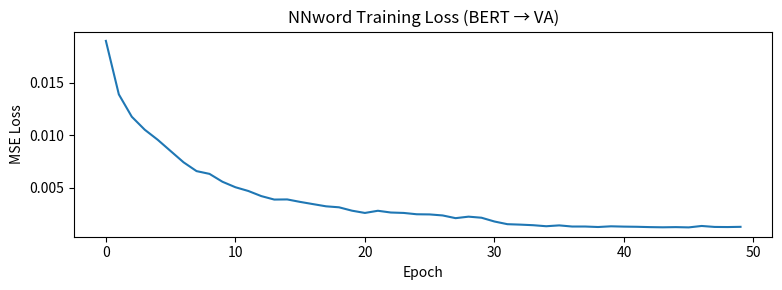

Stage 1 完成


In [ ]:
from torch.utils.data import TensorDataset, DataLoader
model_word = NNword(BERT_DIM).to(device)
opt_word   = optim.AdamW(model_word.parameters(), lr=1e-3, weight_decay=0.01)
sch_word   = optim.lr_scheduler.StepLR(opt_word, step_size=30, gamma=0.5)
# DataLoader（batch training 讓 BatchNorm 正常運作）
word_ds = TensorDataset(wt_v, wt_y_v, wt_y_a)
word_dl = DataLoader(word_ds, batch_size=64, shuffle=True)
print('=== Stage 1：訓練 NNword ===')
N_EPOCHS_WORD = 50
losses_w = []
for epoch in range(N_EPOCHS_WORD):
    model_word.train()
    epoch_loss = 0.0
    for bvec, by_v, by_a in word_dl:
        pred_v, pred_a = model_word(bvec)
        loss = 0.5 * ((pred_v - by_v)**2 + (pred_a - by_a)**2).mean()
        opt_word.zero_grad()
        loss.backward()
        opt_word.step()
        epoch_loss += loss.item()
    sch_word.step()
    avg = epoch_loss / len(word_dl)
    losses_w.append(avg)
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_WORD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_w)
plt.title('NNword Training Loss (BERT → VA)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 1 完成')

## 7. Stage 2：訓練 NNmod（NNword 凍結，直接訓練遞迴鏈）
**v7-2 遞迴鏈訓練流程：**
1. NNword(BERT(core_word)) → Int(w)
2. 由最靠近核心詞的修飾詞開始，逐層遞迴：
   NNmod(Int(current), BERT(modifier [SEP] current_phrase))
3. 以最終 Int(full_phrase) 對齊片語標註 VA
NNword 仍凍結，只訓練 NNmod；但現在訓練時就會展開多層鏈。

=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===
流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)
Epoch  20/100 | Loss: 0.003909
Epoch  40/100 | Loss: 0.002394
Epoch  60/100 | Loss: 0.002142
Epoch  80/100 | Loss: 0.001494
Epoch 100/100 | Loss: 0.001458


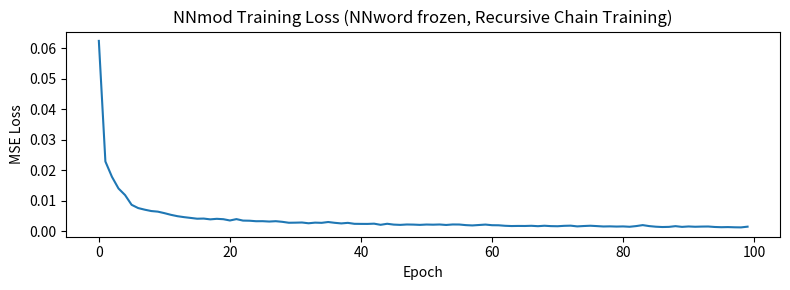

Stage 2 完成


In [ ]:
model_mod = NNmod(BERT_DIM).to(device)
# 凍結 NNword
for param in model_word.parameters():
    param.requires_grad = False
opt_mod = optim.AdamW(model_mod.parameters(), lr=3e-3, weight_decay=1e-4)
print('=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===')
print('流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)')
N_EPOCHS_MOD = 100
losses_m = []
grad_accum_steps = 16
for epoch in range(N_EPOCHS_MOD):
    model_mod.train()
    model_word.eval()
    epoch_loss = 0.0
    idxs = np.random.permutation(len(train_chain_samples))
    opt_mod.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s = train_chain_samples[si]
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        # Step 1：核心詞先經 NNword（固定）
        with torch.no_grad():
            cur_v, cur_a = model_word(core_t)
        # Step 2：沿遞迴鏈逐步套用 NNmod（每步語境都不同）
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, _ = model_mod(cur_v, cur_a, ctx_t)
        # 只用最終 full phrase 監督
        loss = 0.5 * ((cur_v - y_v)**2 + (cur_a - y_a)**2).mean()
        (loss / grad_accum_steps).backward()
        epoch_loss += loss.item()
        if (step_i % grad_accum_steps == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_mod.parameters(), max_norm=1.0)
            opt_mod.step()
            opt_mod.zero_grad()
    avg = epoch_loss / len(train_chain_samples)
    losses_m.append(avg)
    if (epoch + 1) % 20 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_MOD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_m)
plt.title('NNmod Training Loss (NNword frozen, Recursive Chain Training)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 2 完成')

## 8. 預測函式

In [ ]:
@torch.no_grad()
def predict_word_va(word):
    """
    單詞 VA 預測：BERT encode → NNword → (valence, arousal)
    """
    model_word.eval()
    vec = torch.tensor(get_bert_vec(word)).unsqueeze(0).to(device)
    val, aro = model_word(vec)
    return val.item(), aro.item()
@torch.no_grad()
def predict_phrase_va_pipeline(modifier, core_word, verbose=False):
    """
    單層 Pipeline 預測（語境化修飾詞）：
    BERT(core_word) → NNword → Int(w)
    BERT(modifier [SEP] core_word) → NNmod → Int(mod w)
    """
    model_word.eval()
    model_mod.eval()
    # Step 1：核心詞 BERT encode → NNword → Int(w)
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    int_val, int_aro = model_word(core_vec)
    # Step 2：語境化修飾詞 BERT encode → NNmod
    mod_ctx_vec = torch.tensor(get_bert_pair_vec(modifier, core_word)).unsqueeze(0).to(device)
    pred_v, pred_a, c_mod_v, c_mod_a = model_mod(int_val, int_aro, mod_ctx_vec)
    pv, pa = pred_v.item(), pred_a.item()
    iv, ia = int_val.item(), int_aro.item()
    cmv = c_mod_v.item()
    cma = c_mod_a.item()
    if verbose:
        print(f'「{modifier}{core_word}」'
              f'  base(V={iv:.3f},A={ia:.3f})'
              f'  Cmod(V={cmv:.3f},A={cma:.3f})'
              f'  → V={pv:.4f} A={pa:.4f}')
    return pv, pa, cmv, cma
def va_label(v, a):
    pol = '正向' if v>=0.625 else ('負向' if v<=0.375 else '中性')
    act = '高喚起' if a>=0.625 else ('低喚起' if a<=0.375 else '中喚起')
    return f'{pol}/{act}'
# 測試預測
print('=== 單詞預測 ===')
for w in ['開心','難過','憤怒','平靜','興奮','恐懼']:
    v, a = predict_word_va(w)
    print(f'「{w}」V={v:.4f} A={a:.4f} → {va_label(v,a)}')
print()
print('=== Pipeline 片語預測 ===')
for mod, word in [('非常','開心'),('沒有','希望'),('完全','不滿意'),
                  ('極為','不安'),('相當','平靜'),('可能','失望')]:
    pv, pa, cmv, cma = predict_phrase_va_pipeline(mod, word, verbose=True)
    print(f'  → {va_label(pv, pa)} | Cmod(V={cmv:.3f}, A={cma:.3f})')

=== 單詞預測 ===
「開心」V=0.7702 A=0.6939 → 正向/高喚起
「難過」V=0.2802 A=0.5340 → 負向/中喚起
「憤怒」V=0.2097 A=0.7002 → 負向/高喚起
「平靜」V=0.6761 A=0.1679 → 正向/低喚起
「興奮」V=0.7942 A=0.7828 → 正向/高喚起
「恐懼」V=0.2310 A=0.7036 → 負向/高喚起

=== Pipeline 片語預測 ===
「非常開心」  base(V=0.770,A=0.694)  Cmod(V=0.756,A=0.695)  → V=0.8784 A=0.8027
  → 正向/高喚起 | Cmod(V=0.756, A=0.695)
「沒有希望」  base(V=0.731,A=0.527)  Cmod(V=0.001,A=0.419)  → V=0.3778 A=0.4662
  → 中性/中喚起 | Cmod(V=0.001, A=0.419)
「完全不滿意」  base(V=0.411,A=0.347)  Cmod(V=0.190,A=0.787)  → V=0.2156 A=0.5576
  → 負向/中喚起 | Cmod(V=0.190, A=0.787)
「極為不安」  base(V=0.382,A=0.552)  Cmod(V=0.244,A=0.771)  → V=0.2226 A=0.7355
  → 負向/高喚起 | Cmod(V=0.244, A=0.771)
「相當平靜」  base(V=0.676,A=0.168)  Cmod(V=0.616,A=0.466)  → V=0.7472 A=0.1542
  → 正向/低喚起 | Cmod(V=0.616, A=0.466)
「可能失望」  base(V=0.282,A=0.550)  Cmod(V=0.266,A=0.649)  → V=0.1627 A=0.6558
  → 負向/高喚起 | Cmod(V=0.266, A=0.649)


## 9. 多修飾詞遞迴預測（論文 Fig. 4）
每層輸出 VA 傳入下一層，逐層套用修飾詞。  
v7-2 在每一層都用 `BERT(modifier [SEP] 當前片語)` 重新編碼，
避免同一個副詞在不同語境得到完全相同表示。

In [ ]:
@torch.no_grad()
def predict_multi_mod_pipeline(modifiers, core_word):
    """
    多修飾詞遞迴 Pipeline（對應論文 Fig. 4）：
    由最靠近核心詞的修飾詞（列表最右）開始，逐層向外套用。
    語境化版本：每層使用 BERT(modifier [SEP] 當前片語)
    """
    model_word.eval()
    model_mod.eval()
    phrase_str = ''.join(modifiers) + core_word
    print(f'\n多修飾詞遞迴：「{phrase_str}」')
    # 第一步：核心詞走 BERT + NNword
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    cur_v, cur_a = model_word(core_vec)
    print(f'  核心詞「{core_word}」→ V={cur_v.item():.4f} A={cur_a.item():.4f}')
    cur_label = core_word
    # 從最靠近核心詞的修飾詞開始，逐層向外（reversed）
    for i, mod in enumerate(reversed(modifiers)):
        mod_ctx_vec = torch.tensor(get_bert_pair_vec(mod, cur_label)).unsqueeze(0).to(device)
        new_v, new_a, c_mod_v, c_mod_a = model_mod(cur_v, cur_a, mod_ctx_vec)
        print(f'  +「{mod}」[mod_{len(modifiers)-i}] '
              f'V:{cur_v.item():.4f}→{new_v.item():.4f}  '
              f'A:{cur_a.item():.4f}→{new_a.item():.4f}  '
              f'[Cv={c_mod_v.item():.3f}, Ca={c_mod_a.item():.3f}]')
        cur_v, cur_a = new_v, new_a
        cur_label = mod + cur_label
    final_v, final_a = cur_v.item(), cur_a.item()
    print(f'  最終「{phrase_str}」→ V={final_v:.4f} A={final_a:.4f}  {va_label(final_v, final_a)}')
    return final_v, final_a
# 測試（對應論文 Fig. 4 的 would not very good）
predict_multi_mod_pipeline(['應該','沒有','非常'], '開心')
predict_multi_mod_pipeline(['完全','不'],          '滿意')
predict_multi_mod_pipeline(['可能','更加'],        '不安')


多修飾詞遞迴：「應該沒有非常開心」
  核心詞「開心」→ V=0.7702 A=0.6939
  +「非常」[mod_3] V:0.7702→0.8784  A:0.6939→0.8027  [Cv=0.756, Ca=0.695]
  +「沒有」[mod_2] V:0.8784→0.6194  A:0.8027→0.5651  [Cv=0.003, Ca=0.119]
  +「應該」[mod_1] V:0.6194→0.5066  A:0.5651→0.5088  [Cv=0.346, Ca=0.424]
  最終「應該沒有非常開心」→ V=0.5066 A=0.5088  中性/中喚起

多修飾詞遞迴：「完全不滿意」
  核心詞「滿意」→ V=0.6289 A=0.4358
  +「不」[mod_2] V:0.6289→0.2882  A:0.4358→0.5502  [Cv=0.023, Ca=0.653]
  +「完全」[mod_1] V:0.2882→0.1440  A:0.5502→0.7365  [Cv=0.207, Ca=0.775]
  最終「完全不滿意」→ V=0.1440 A=0.7365  負向/高喚起

多修飾詞遞迴：「可能更加不安」
  核心詞「不安」→ V=0.3818 A=0.5525
  +「更加」[mod_2] V:0.3818→0.2393  A:0.5525→0.7020  [Cv=0.275, Ca=0.715]
  +「可能」[mod_1] V:0.2393→0.2186  A:0.7020→0.7372  [Cv=0.461, Ca=0.558]
  最終「可能更加不安」→ V=0.2186 A=0.7372  負向/高喚起


(0.21858443319797516, 0.7372035384178162)

## 10. 評估函式

In [ ]:
def compute_metrics(preds, golds, label):
    """
    Chinese EmoBank 論文指標：MAE、Pearson r
    Pipelined NN 論文指標：Kendall τ、Spearman ρ
    額外：MSE
    """
    p = np.array(preds); g = np.array(golds)
    mae    = np.mean(np.abs(p - g))
    mse    = np.mean((p - g) ** 2)
    r, _   = pearsonr(p, g)
    tau, _ = kendalltau(p, g)
    rho, _ = spearmanr(p, g)
    print(f'  {label:30s} | MAE={mae:.4f}  MSE={mse:.4f}  r={r:.4f}  τ={tau:.4f}  ρ={rho:.4f}')
    return mae, mse, r, tau, rho
@torch.no_grad()
def batch_predict_word(vecs_np):
    model_word.eval()
    t = torch.tensor(vecs_np).to(device)
    pv, pa = model_word(t)
    return pv.cpu().numpy().flatten(), pa.cpu().numpy().flatten()
@torch.no_grad()
def batch_predict_phrase_recursive(samples, return_shift=False):
    """
    用與 Stage 2 相同的遞迴鏈路徑評估：
    core -> NNword -> NNmod(step1..stepN)
    """
    model_word.eval(); model_mod.eval()
    all_pv, all_pa = [], []
    all_cmv, all_cma = [], []
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        last_cmv = torch.tensor([[0.5]], device=device)
        last_cma = torch.tensor([[0.5]], device=device)
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, last_cmv, last_cma = model_mod(cur_v, cur_a, ctx_t)
        all_pv.append(cur_v.item())
        all_pa.append(cur_a.item())
        all_cmv.append(last_cmv.item())
        all_cma.append(last_cma.item())
    pv = np.array(all_pv, dtype=np.float32)
    pa = np.array(all_pa, dtype=np.float32)
    if return_shift:
        cmv = np.array(all_cmv, dtype=np.float32)
        cma = np.array(all_cma, dtype=np.float32)
        return pv, pa, cmv, cma
    return pv, pa

## 11. 訓練集評估

In [ ]:
print('='*75)
print('【訓練集評估】')
print('='*75)
# NNword 訓練集
print('\n[NNword] CVAW 訓練集')
pv_trw, pa_trw = batch_predict_word(word_train_vecs)
compute_metrics(pv_trw, word_train_val, 'Valence')
compute_metrics(pa_trw, word_train_aro, 'Arousal')
# Pipeline 訓練集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 訓練集')
pv_trm, pa_trm = batch_predict_phrase_recursive(train_chain_samples)
compute_metrics(pv_trm, phrase_train_val, 'Valence')
compute_metrics(pa_trm, phrase_train_aro, 'Arousal')

【訓練集評估】

[NNword] CVAW 訓練集
  Valence                        | MAE=0.0168  MSE=0.0005  r=0.9952  τ=0.9421  ρ=0.9935
  Arousal                        | MAE=0.0217  MSE=0.0008  r=0.9907  τ=0.9269  ρ=0.9905

[Pipeline-Recursive] CVAP 訓練集
  Valence                        | MAE=0.0234  MSE=0.0013  r=0.9876  τ=0.9121  ρ=0.9841
  Arousal                        | MAE=0.0231  MSE=0.0009  r=0.9809  τ=0.8777  ρ=0.9788


(np.float32(0.02307676),
 np.float32(0.00087034574),
 np.float32(0.9809109),
 np.float64(0.8776937253219078),
 np.float64(0.9788272173839438))

## 12. 測試集評估

In [ ]:
print('='*75)
print('【測試集評估】')
print('='*75)
# NNword 測試集
print('\n[NNword] CVAW 測試集')
pv_tew, pa_tew = batch_predict_word(word_test_vecs)
compute_metrics(pv_tew, word_test_val, 'Valence')
compute_metrics(pa_tew, word_test_aro, 'Arousal')
# Pipeline 測試集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 測試集')
pv_tem, pa_tem = batch_predict_phrase_recursive(test_chain_samples)
compute_metrics(pv_tem, phrase_test_val, 'Valence')
compute_metrics(pa_tem, phrase_test_aro, 'Arousal')

【測試集評估】

[NNword] CVAW 測試集
  Valence                        | MAE=0.0759  MSE=0.0104  r=0.8666  τ=0.6507  ρ=0.8355
  Arousal                        | MAE=0.1116  MSE=0.0204  r=0.6221  τ=0.4352  ρ=0.6036

[Pipeline-Recursive] CVAP 測試集
  Valence                        | MAE=0.0520  MSE=0.0052  r=0.9441  τ=0.8005  ρ=0.9395
  Arousal                        | MAE=0.0525  MSE=0.0044  r=0.9025  τ=0.7124  ρ=0.8880


(np.float32(0.052461557),
 np.float32(0.00439792),
 np.float32(0.90251863),
 np.float64(0.7123656580200562),
 np.float64(0.8880427725759203))

## 13. 結果摘要表 + 視覺化

In [ ]:
def metrics(p, g):
    pa = np.array(p); ga = np.array(g)
    mae    = np.mean(np.abs(pa - ga))
    mse    = np.mean((pa - ga)**2)
    r, _   = pearsonr(pa, ga)
    tau, _ = kendalltau(pa, ga)
    rho, _ = spearmanr(pa, ga)
    return round(mae,4), round(mse,4), round(r,4), round(tau,4), round(rho,4)
rows = [
    ('NNword',   '訓練', 'Valence', *metrics(pv_trw, word_train_val)),
    ('NNword',   '訓練', 'Arousal', *metrics(pa_trw, word_train_aro)),
    ('NNword',   '測試', 'Valence', *metrics(pv_tew, word_test_val)),
    ('NNword',   '測試', 'Arousal', *metrics(pa_tew, word_test_aro)),
    ('Pipeline', '訓練', 'Valence', *metrics(pv_trm, phrase_train_val)),
    ('Pipeline', '訓練', 'Arousal', *metrics(pa_trm, phrase_train_aro)),
    ('Pipeline', '測試', 'Valence', *metrics(pv_tem, phrase_test_val)),
    ('Pipeline', '測試', 'Arousal', *metrics(pa_tem, phrase_test_aro)),
]
summary = pd.DataFrame(rows,
    columns=['模型','資料集','維度','MAE','MSE','Pearson r','Kendall τ','Spearman ρ'])
print(summary.to_string(index=False))

      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0168 0.0005     0.9952     0.9421      0.9935
  NNword  訓練 Arousal 0.0217 0.0008     0.9907     0.9269      0.9905
  NNword  測試 Valence 0.0759 0.0104     0.8666     0.6507      0.8355
  NNword  測試 Arousal 0.1116 0.0204     0.6221     0.4352      0.6036
Pipeline  訓練 Valence 0.0234 0.0013     0.9876     0.9121      0.9841
Pipeline  訓練 Arousal 0.0231 0.0009     0.9809     0.8777      0.9788
Pipeline  測試 Valence 0.0520 0.0052     0.9441     0.8005      0.9395
Pipeline  測試 Arousal 0.0525 0.0044     0.9025     0.7124      0.8880


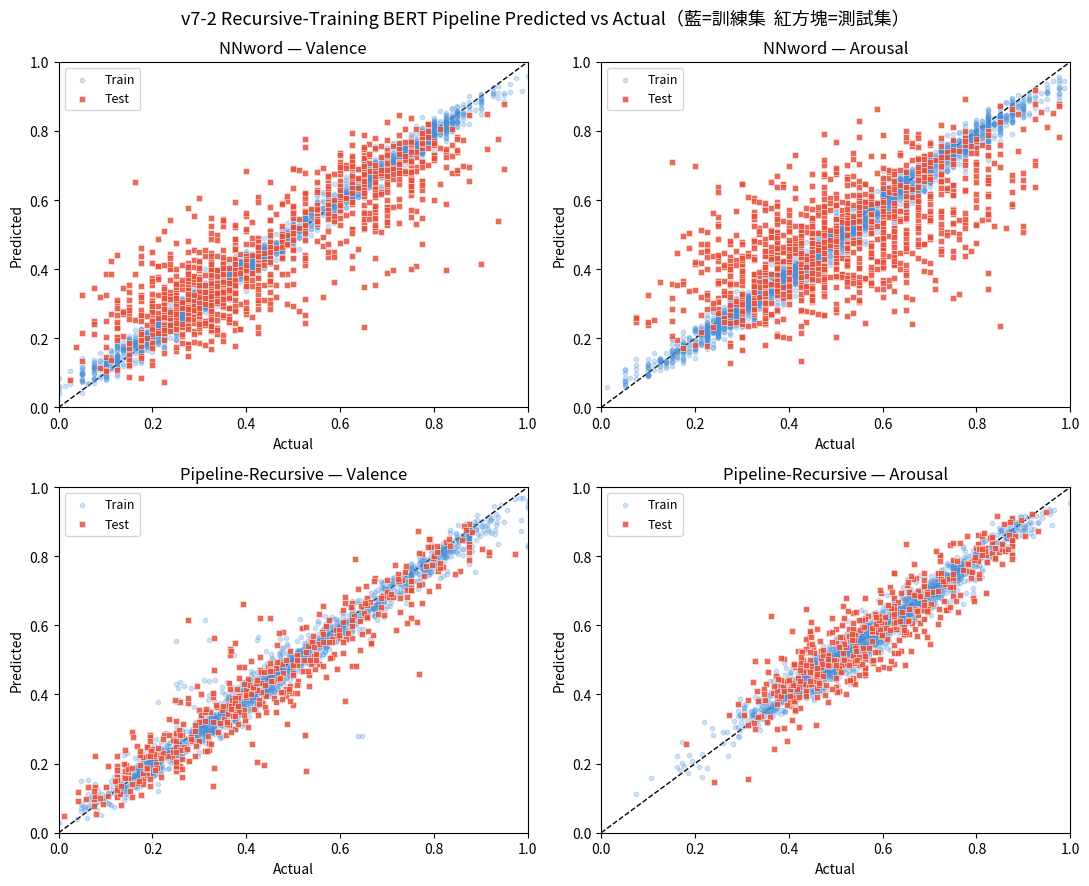

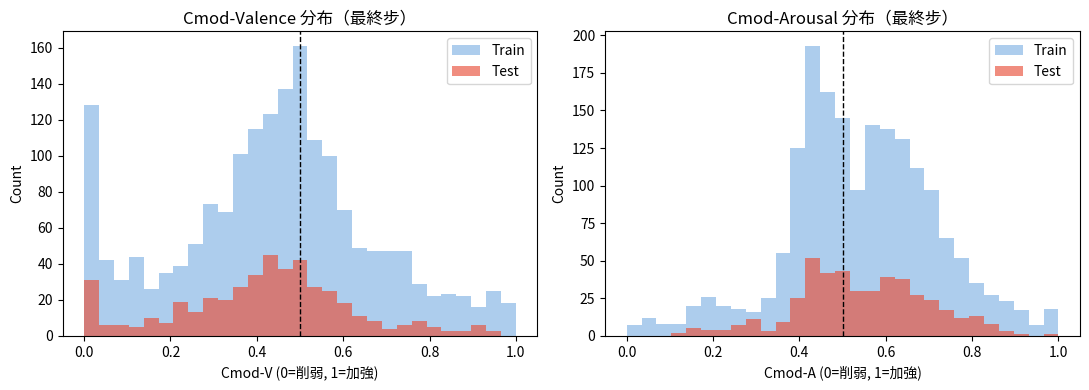

Test Cmod-V mean=0.419, std=0.205
Test Cmod-A mean=0.544, std=0.152


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle('v7-2 Recursive-Training BERT Pipeline Predicted vs Actual（藍=訓練集  紅方塊=測試集）', fontsize=13)
configs = [
    (axes[0,0], pv_trw, word_train_val, pv_tew, word_test_val, 'NNword — Valence',   '#4A90D9', '#E8503A'),
    (axes[0,1], pa_trw, word_train_aro, pa_tew, word_test_aro, 'NNword — Arousal',   '#4A90D9', '#E8503A'),
    (axes[1,0], pv_trm, phrase_train_val, pv_tem, phrase_test_val, 'Pipeline-Recursive — Valence', '#4A90D9', '#E8503A'),
    (axes[1,1], pa_trm, phrase_train_aro, pa_tem, phrase_test_aro, 'Pipeline-Recursive — Arousal', '#4A90D9', '#E8503A'),
]
for ax, ptr, gtr, pte, gte, title, c_tr, c_te in configs:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color=c_tr, label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color=c_te, marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0,1],[0,1],'k--', linewidth=1, zorder=1)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()
# c_mod 雙維度視覺化（Valence shift / Arousal shift）
_, _, cmv_tr, cma_tr = batch_predict_phrase_recursive(train_chain_samples, return_shift=True)
_, _, cmv_te, cma_te = batch_predict_phrase_recursive(test_chain_samples, return_shift=True)
fig2, axes2 = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0.0, 1.0, 30)
axes2[0].hist(cmv_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[0].hist(cmv_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[0].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[0].set_title('Cmod-Valence 分布（最終步）')
axes2[0].set_xlabel('Cmod-V (0=削弱, 1=加強)')
axes2[0].set_ylabel('Count')
axes2[0].legend()
axes2[1].hist(cma_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[1].hist(cma_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[1].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[1].set_title('Cmod-Arousal 分布（最終步）')
axes2[1].set_xlabel('Cmod-A (0=削弱, 1=加強)')
axes2[1].set_ylabel('Count')
axes2[1].legend()
plt.tight_layout(); plt.show()
print(f'Test Cmod-V mean={cmv_te.mean():.3f}, std={cmv_te.std():.3f}')
print(f'Test Cmod-A mean={cma_te.mean():.3f}, std={cma_te.std():.3f}')

## [新增] NNword / NNmod 預測 VA 分布散佈圖（仿論文 Fig. 3 樣式）

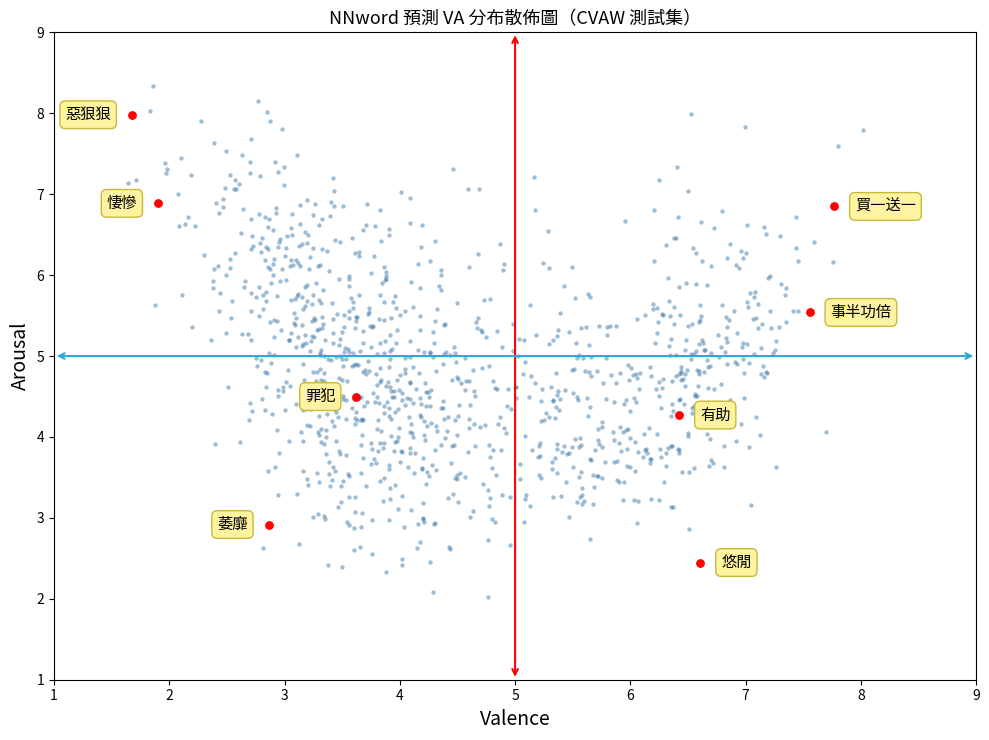

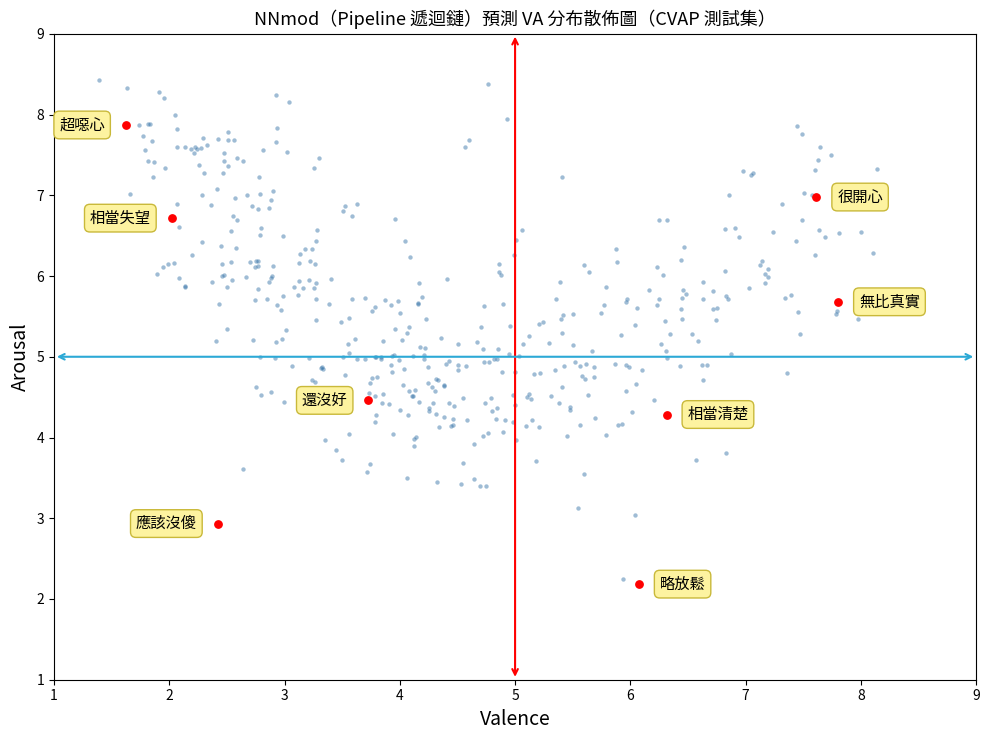

In [ ]:
plot_va_scatter(pv_tew, pa_tew, cvaw_test['Word'].tolist(),
                'NNword 預測 VA 分布散佈圖（CVAW 測試集）', savepath='nnword_va_scatter.png')
plot_va_scatter(pv_tem, pa_tem, [s['full_phrase'] for s in test_chain_samples],
                'NNmod（Pipeline 遞迴鏈）預測 VA 分布散佈圖（CVAP 測試集）', savepath='nnmod_va_scatter.png')

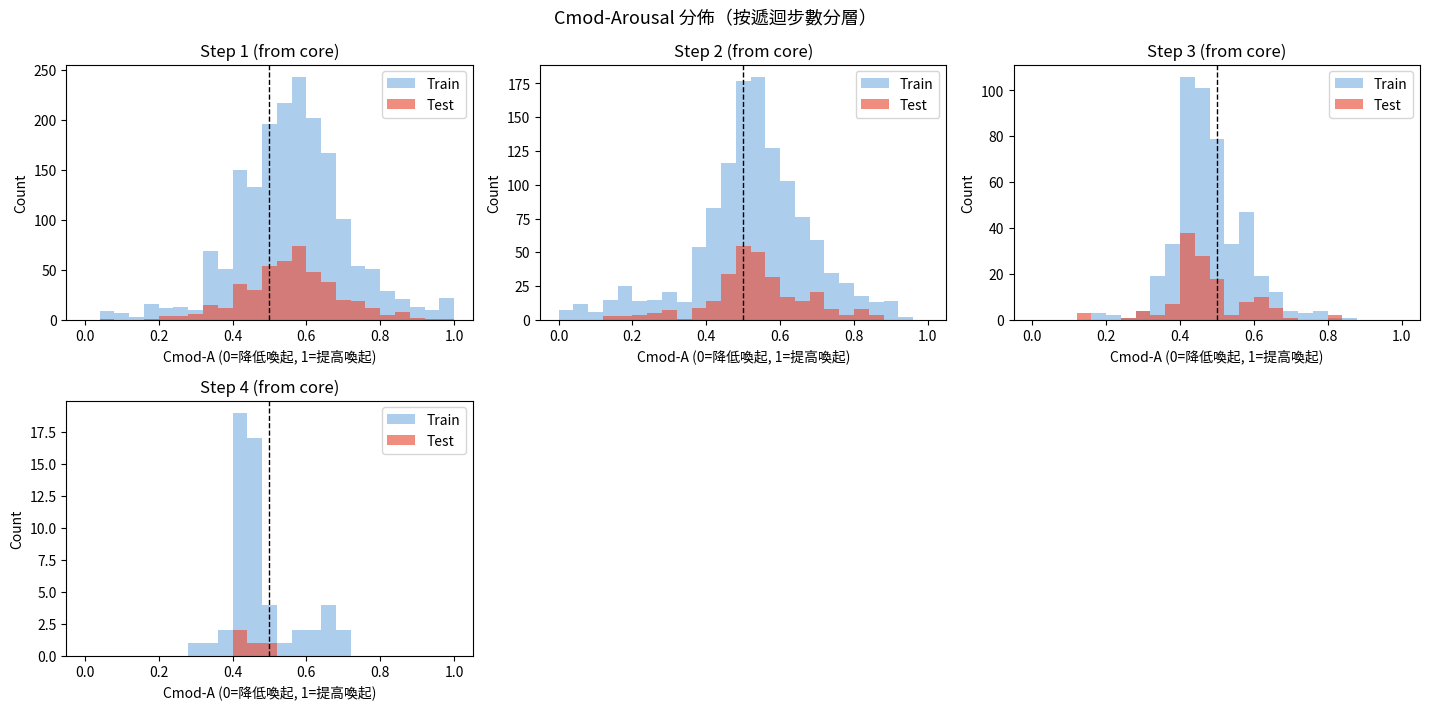

=== 每一步 Cmod-A 統計（Test）===
Step 1: mean=0.558, std=0.130, n=450
Step 2: mean=0.537, std=0.135, n=293
Step 3: mean=0.469, std=0.107, n=129
Step 4: mean=0.452, std=0.029, n=4


In [ ]:
@torch.no_grad()
def collect_cmod_a_by_step(samples):
    model_word.eval()
    model_mod.eval()
    step_to_vals = {}
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        for step_idx, ctx_np in enumerate(s['ctx_chain'], start=1):
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, c_mod_a = model_mod(cur_v, cur_a, ctx_t)
            step_to_vals.setdefault(step_idx, []).append(c_mod_a.item())
    return {k: np.array(v, dtype=np.float32) for k, v in step_to_vals.items()}

train_a_by_step = collect_cmod_a_by_step(train_chain_samples)
test_a_by_step = collect_cmod_a_by_step(test_chain_samples)
all_steps = sorted(set(train_a_by_step.keys()) | set(test_a_by_step.keys()))
if not all_steps:
    raise ValueError('沒有可用的遞迴步數資料，請先確認 train_chain_samples / test_chain_samples。')
n_steps = len(all_steps)
n_cols = min(3, n_steps)
n_rows = int(np.ceil(n_steps / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.8 * n_cols, 3.6 * n_rows), squeeze=False)
bins = np.linspace(0.0, 1.0, 26)
for i, step in enumerate(all_steps):
    r = i // n_cols
    c = i % n_cols
    ax = axes[r, c]
    tr = train_a_by_step.get(step, np.array([], dtype=np.float32))
    te = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(tr) > 0:
        ax.hist(tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
    if len(te) > 0:
        ax.hist(te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
    ax.axvline(0.5, color='k', linestyle='--', linewidth=1)
    ax.set_title(f'Step {step} (from core)')
    ax.set_xlabel('Cmod-A (0=降低喚起, 1=提高喚起)')
    ax.set_ylabel('Count')
    ax.legend()
for j in range(n_steps, n_rows * n_cols):
    rr = j // n_cols
    cc = j % n_cols
    axes[rr, cc].axis('off')
fig.suptitle('Cmod-Arousal 分佈（按遞迴步數分層）', fontsize=13)
plt.tight_layout()
plt.show()
print('=== 每一步 Cmod-A 統計（Test）===')
for step in all_steps:
    vals = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(vals) == 0:
        continue
    print(f'Step {step}: mean={vals.mean():.3f}, std={vals.std():.3f}, n={len(vals)}')

## 14. Stage 3：擴充到 CVAS 句子層級（NNword / NNmod 完全不動，僅新增）

**設計原則（v7-3b：實測後再修正的版本）：**
```
Stage 1（不動）：BERT(word) -> NNword -> Int(w)
Stage 2（不動）：BERT(core) -> NNword(frozen) -> Int(w)
                 BERT(modifier [SEP] core/phrase) -> NNmod(frozen) -> Int(mod phrase)
Stage 3（新增，v7-3b 修正版）：
  句子 -> 滑動窗口切出「情感詞」與「修飾詞+情感詞」候選 span（依句子中出現順序）
       -> 有修飾詞的 span：走 Stage1+2 的遞迴鏈（NNword、NNmod 全程凍結，
          只是「借用」它們算出來的 VA / c_mod，權重完全不變）
       -> 沒有修飾詞的 span（只有核心詞）：先用這個詞「孤立向量」的
          NNword 估計當先驗，再交給 NNsent 內建的一個小 context adapter，
          用整句 BERT 向量算一個殘差修正（詳見下方 v7-3b 修正說明）
       -> NNsent：依 span 順序做「遞迴鏈」聚合（跟 NNmod 處理修飾詞鏈的
          寫法完全一致，而不是更早版本的 attention 加權平均），逐步把
          每個 span 的資訊套用到一個持續更新的句子狀態上
       -> 最終再讓 Valence 狀態去修正一次 Arousal（V 幫助 A）
```

**這一版（v7-3）跟指導教授討論後修正的三個地方：**
1. **`hit=0`（沒有修飾詞）的 span，VA 要參考整句語境，而非只用孤立詞向量**
2. **NNsent 改成跟 NNmod 一樣的「遞迴鏈」設計**——捨棄更早版本「所有 span
   當無序集合做 attention 加權平均」的做法，改成依照 span 在句子中出現
   的順序，逐步把每個 span 的資訊套用到一個持續更新的句子狀態上（寫法、
   logit 空間殘差平移方式都跟 NNmod 一致），這樣句子裡的順序、轉折
   （例如「一開始...後來卻...」）才有機會被模型看到。
3. **Arousal 最終再吃一次 Valence 狀態做修正（V 幫助 A）**——訊號天花板
   診斷（見 14.4）顯示 Arousal 單獨從詞彙訊號預測的能力遠弱於 Valence，
   因此讓已經學得比較好的 Valence 狀態去輔助修正 Arousal。

**v7-3b：第 1 點的修正說明（實測後再調整）——**
第一版做法是把整句 BERT 向量直接餵給 model_word（NNword）。但 model_word
從頭到尾只在「單一詞彙」的 BERT 向量上訓練過，從沒看過完整句子的 [CLS]
向量長什麼樣子——對一個沒看過的輸入分布，凍結的網路很容易塌陷回它學到
的「安全平均值」，實測結果也證實了這點：Valence 有進步，但 Arousal 的
預測幾乎壓平在一個很窄的範圍，跟訊號天花板診斷顯示的「Arousal 訊號本來
就比 Valence 弱」疊加在一起，OOD 塌陷的問題更明顯。

修正做法：不再把整句向量直接塞給 model_word，而是新增一個小的、獨立
訓練的 **context adapter**（`SentContextAdapter`，定義在 NNsent 內）：
  - 先用 `get_core_vec_cached(core)` 算出這個詞「孤立向量」的 NNword
    估計 `(v_word, a_word)` 當先驗起點——這就是更早版本、也是 v7-2 原本
    的做法，穩定但沒有語境。
  - 再把整句 BERT 向量、跟這個先驗一起交給 adapter，讓 adapter 自己
    學一個小小的殘差修正（寫法跟 NNmod／NNsent 每一步一致：logit 空間
    殘差平移，`tanh(...)*0.5` 限制修正幅度）。
  - adapter 的權重是全新初始化、隨 NNsent 一起訓練的（不是凍結的
    model_word 本身），所以剛開始訓練時 delta≈0，等於先退化成孤立詞
    估計，不會比舊版更差；隨著訓練才會學到「這句話的語境該往哪個方向
    修正」。
  - 有修飾詞的 span、以及極少數（<0.1%）沒對到任何 CVAW 詞的 fallback
    span，做法不變，不經過這個 adapter。

**「哪些詞有幫助 VA 預測、哪些沒作用」怎麼判斷（14.6，設計不變）：**
1. **NNsent 每一步的 contribution**（取代舊版 attention weight）—— 這個 span
   被套用到句子狀態時，模型算出的偏移量有多大（0.5=沒影響，偏離 0.5 越
   遠代表這一步影響句子情緒越大），寫法跟 NNmod 的 `c_mod` 完全對應。
2. **Leave-One-Out（LOO）消融** —— 把某個 span 從「依序」的 span 序列中
   整個拿掉（因為現在是遞迴鏈，拿掉一個 span 後面所有步驟的狀態都會跟著
   改變），重新跑一次完整序列，量測整句 VA 的變化量 ΔV / ΔA。
3. 把兩者結合，並在整個測試集上依「情感詞（核心詞）」「修飾詞」分組取
   平均，就能得到一張「哪些詞平均而言有用／沒用」的排行榜。

`NNword` / `NNmod` 兩個 class 與 `model_word` / `model_mod` 兩個訓練好的模型
完全沒有被修改或重新訓練。

## 14.1 CVAS 前處理（正規化 + 切分，沿用 cell 5 的 `normalize_va`，不重新定義）

In [ ]:
# cell 3 只載入了 cvas，cell 5 只正規化/切分了 cvaw、cvap
# （v7-2 原版沒有用到 CVAS）；這裡把同一套流程套用在 cvas 上
cvas = normalize_va(cvas)
cvas_train_full, cvas_test = train_test_split(cvas, test_size=0.2, random_state=42)
# [新增 v7-3c] 再從訓練集切一份驗證集出來——完全不參與梯度更新，只在每個 epoch
# 結束後拿來監控 NNsent 有沒有 overfitting（訓練集學得很好、驗證集卻沒有跟著變好，
# 就是過擬合的訊號），並用來挑「驗證損失最低」的那個 epoch 的權重。cvas_test 維持
# 完全不動，只在全部訓練結束後拿來做最終、只看一次的效能報告。
cvas_train, cvas_val = train_test_split(cvas_train_full, test_size=0.15, random_state=42)
print(f'CVAS 訓練:{len(cvas_train)}  驗證:{len(cvas_val)}  測試:{len(cvas_test)}')
print(cvas_train[['Text', 'valence', 'arousal']].head().to_string(index=False))

CVAS 訓練:1756  驗證:310  測試:517
              Text  valence  arousal
整個官僚機制和國民內鬥的齒輪咬合咬合 0.312500 0.625000
           王岐山器重明鏡 0.625000 0.312500
        偶爾在陰雨綿綿的夜晚 0.425000 0.281250
         如果我果斷獨自沉澱 0.416625 0.333375
       但情人海灘仍然美得驚人 0.875000 0.800000


## 14.2 句子 → 情感 span 切割 + Stage1+2 遞迴 Pipeline
借用 `model_word` / `model_mod` 的 VA 輸出，兩者權重完全不變。

In [ ]:
# 沿用 cell 5 的 split_phrase / cvaw_word_set / max_core_len，完全不改
# 沿用 cell 12 的 get_core_vec_cached / get_pair_vec_cached（BERT 向量快取，避免重算）
# 沿用 cell 10 定義、cell 14 / 16 訓練好的 model_word / model_mod（此處只做 eval，全程凍結）

MAX_SPANS  = 8   # 一句最多取幾個情感 span
MOD_WINDOW = 6   # 情感詞往前找修飾詞的視窗大小（字數）


@torch.no_grad()
def run_full_pipeline(span_text, mod, core, chain, sentence_vec=None):
    """
    對一個文字片段（情感詞，或「修飾詞+情感詞」）執行完整 Stage1+2 遞迴鏈。
    NNword / NNmod 全程凍結、權重不變，這裡只是「借用」它們的推論結果。

    mod/core/chain 必須是呼叫方（`extract_emotion_spans`）已經切好的結果，
    直接傳進來用——不能在這裡重新呼叫 `split_phrase(span_text, ...)` 重切一次。
    這是 v7-3b 修過的一個 bug：`split_phrase` 的迴圈是
    `upper = min(max_core_len, len(phrase) - 1)`，也就是**規定一定要有
    非空的修飾詞前綴**才會嘗試任何候選（CVAP 短語本來就都是「修飾詞+詞」
    的結構，所以原本這樣設計沒問題）。但如果把一個「只有核心詞、沒有修飾詞」
    的裸詞（例如 extract_emotion_spans 已經確定沒找到修飾詞的 span_text）
    重新丟進 split_phrase 切一次，因為它自己就是核心詞、前面沒有任何字，
    這個迴圈直接是空的，一定回傳 `(None, None, [])`——等於把所有「核心詞、
    無修飾詞」的 span 都誤判成 kind='fallback'，也就是這個 span 原本該走的
    context adapter（見下面 kind='core'）從來沒被用到過，而且同一句話裡
    好幾個這種 span 會全部退化成同一個「整句向量」估計，數值會一模一樣。

    回傳一個 dict，'kind' 決定 14.4 該怎麼組 span_feats：
      kind='mod'     : {'v','a','cmv','cma','hit'=1}
                       有找到修飾詞，走完整 NNword -> NNmod 遞迴鏈，
                       這裡算出來的就是最終值，不需要再修正。
      kind='core'    : {'v_word','a_word','ctx','hit'=0}
                       只有核心詞、沒有修飾詞——v_word/a_word 是這個詞
                       「孤立向量」的 NNword 估計（跟 v7-2 原本做法一樣，
                       當先驗），ctx 是整句 BERT 向量，原封不動交給 14.3
                       NNsent 內建的 context adapter，由 adapter 自己決定
                       要不要、要修正多少（不在這裡直接把整句向量塞進
                       只在單一詞彙向量上訓練過的 model_word——那樣的
                       輸入分布 model_word 沒看過，容易塌陷回安全的平均值，
                       這是實測後跟指導教授討論再修正的地方）。
      kind='fallback': {'v','a','cmv','cma','hit'=0}
                       這個片段裡沒有 CVAW 詞，樣本極少（<0.1%），直接用
                       整句向量餵 model_word，不特別處理。
    """
    model_word.eval(); model_mod.eval()

    if core is not None and mod:
        # 有修飾詞 → 完整遞迴鏈（跟 Stage2 訓練時走的路徑一致，不變）
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        cur_label = core
        cmv = torch.tensor([[0.5]], device=device)
        cma = torch.tensor([[0.5]], device=device)
        for m in reversed(chain):
            ctx_t = torch.tensor(get_pair_vec_cached(str(m), cur_label)).unsqueeze(0).to(device)
            cv, ca, cmv, cma = model_mod(cv, ca, ctx_t)
            cur_label = str(m) + cur_label
        return {'kind': 'mod', 'v': cv.item(), 'a': ca.item(),
                'cmv': cmv.item(), 'cma': cma.item(), 'hit': 1}

    elif core is not None:
        # 只有核心詞、沒有修飾詞 → 孤立詞估計當先驗，整句向量留給 context adapter
        ct = torch.tensor(get_core_vec_cached(core)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        ctx_np = sentence_vec if sentence_vec is not None else get_bert_vec(span_text)
        return {'kind': 'core', 'v_word': cv.item(), 'a_word': ca.item(),
                'ctx': ctx_np, 'hit': 0}

    else:
        # 這個片段裡沒有 CVAW 情感詞 → 直接用整句向量做 NNword 估計
        vec_np = sentence_vec if sentence_vec is not None else get_bert_vec(span_text)
        vec = torch.tensor(vec_np).unsqueeze(0).to(device)
        cv, ca = model_word(vec)
        return {'kind': 'fallback', 'v': cv.item(), 'a': ca.item(),
                'cmv': 0.5, 'cma': 0.5, 'hit': 0}


def build_span_feats_for_sentence(sentence, max_spans=MAX_SPANS):
    """
    對一句話跑 span 切割 + Stage1+2 pipeline，組出 NNsent 吃的 span_feats。
    14.4 的訓練資料建構、14.6 demo 函式共用這個函式，避免兩邊邏輯後續改壞。

    span_feats 每個元素是 (v, a, cmv, cma, hit, ctx) 6-tuple：
      ctx is None  → v/a/cmv/cma 已經是 run_full_pipeline 算好的最終值
                      （mod 或 fallback 分支），NNsent 直接拿去用。
      ctx is not None → v/a 是「孤立向量」NNword 估計（先驗），cmv/cma 是
                      占位值（NNsent 內的 context adapter 會重新算出
                      實際要用的 cmv/cma），ctx 是整句 BERT 向量。
    """
    sentence = str(sentence)
    span_items = extract_emotion_spans(sentence, cvaw_word_set, max_spans)
    sentence_vec = get_bert_vec(sentence)

    span_feats, span_infos = [], []
    counts = {'full': 0, 'core': 0, 'fb': 0}
    for span_text, mod, core, chain in span_items:
        r = run_full_pipeline(span_text, mod, core, chain, sentence_vec=sentence_vec)
        if r['kind'] == 'mod':
            span_feats.append((r['v'], r['a'], r['cmv'], r['cma'], r['hit'], None))
            counts['full'] += 1
        elif r['kind'] == 'core':
            span_feats.append((r['v_word'], r['a_word'], 0.5, 0.5, r['hit'], r['ctx']))
            counts['core'] += 1
        else:
            span_feats.append((r['v'], r['a'], r['cmv'], r['cma'], r['hit'], None))
            counts['fb'] += 1
        span_infos.append({'span_text': span_text, 'modifier': mod, 'core_word': core, 'hit': r['hit']})

    return span_feats, span_infos, counts


def extract_emotion_spans(sentence, cvaw_words, max_spans=MAX_SPANS, mod_window=MOD_WINDOW):
    """
    滑動窗口掃描句子（由左至右）：找出每個出現在 CVAW 詞典裡的情感詞，
    再往前嘗試組出「修飾詞+情感詞」的完整短語（用 split_phrase 驗證，
    且要求修飾詞鏈裡每個 token 都必須是 MODIFIER_LEXICON 認得的否定/程度詞，
    避免把句子裡任意的前置字誤判成修飾詞 —— split_phrase 的 fallback
    原本是為了短 CVAP 片語設計的，直接套在長很多的句子窗口上容易誤判）。

    回傳的 span 依照在句子中「出現的先後順序」排列（由左至右掃描，依序
    append），14.3 的 NNsent 遞迴鏈就是依照這個順序逐步處理。

    沒被任何 span 涵蓋到的字，代表它從一開始就沒有進入 pipeline ——
    這本身就是「這個詞對 VA 預測沒有直接作用」的一種訊號
    （涵蓋率統計見 14.4 的 cnt_full / cnt_core / cnt_fb）。
    """
    sentence = str(sentence).strip()
    found_spans = []
    visited_pos = set()

    i = 0
    while i < len(sentence):
        matched_core = None
        matched_len = 0
        for cl in range(min(max_core_len, len(sentence) - i), 0, -1):
            if sentence[i:i + cl] in cvaw_words:
                matched_core = sentence[i:i + cl]
                matched_len = cl
                break

        if matched_core and i not in visited_pos:
            visited_pos.add(i)
            best_span = (matched_core, None, matched_core, [])
            for start in range(max(0, i - mod_window), i + 1):
                candidate = sentence[start:i + matched_len]
                m, c, ch = split_phrase(candidate, cvaw_words)
                # split_phrase() 的 fallback 會把「沒認得的字」也塞進 modifier_chain
                # （見 cell 5 split_modifier_chain 的 else 分支），對短 CVAP 片語還好，
                # 但套在長很多的句子窗口上，會把任意前綴字誤判成「修飾詞」。
                # 這裡額外要求 chain 裡每個 token 都必須是真正的否定/程度詞，
                # 才承認這是一個有效的「修飾詞+情感詞」span，否則視同沒找到修飾詞。
                if c == matched_core and m and ch and all(t in MODIFIER_LEXICON for t in ch):
                    best_span = (m + c, m, c, ch)
                    break
            if best_span[0] not in [s[0] for s in found_spans]:
                found_spans.append(best_span)
            i += matched_len
        else:
            i += 1

    if not found_spans:
        found_spans = [(sentence, None, None, [])]

    return found_spans[:max_spans]


print('extract_emotion_spans / run_full_pipeline 定義完成')

extract_emotion_spans / run_full_pipeline 定義完成


## 14.3 NNsent：句子層級聚合（v7-3b：遞迴鏈 + context adapter）

捨棄更早版本「所有 span 當無序集合做 attention 加權平均」的設計，改成
跟 `NNmod` 完全一樣的「遞迴鏈」模式：依照 span 在句子中出現的順序
（`extract_emotion_spans` 已經由左至右排好），把每個 span 的資訊，用
跟 NNmod 一模一樣的「logit 空間殘差平移」方式，逐步套用到一個持續更新
的句子狀態 `(cur_v, cur_a)` 上——這樣句子裡的順序、轉折（例如「一開始
...後來卻...」）才有機會被模型看到，而不是把所有 span 的順序資訊丟掉。

每一步輸入：目前狀態 `(cur_v, cur_a)` ⊕ 這個 span 的資訊
（VA(2) + c_mod(2) + hit(1) = 5 維，`hit=0` 代表沒有修飾詞可用）。
每一步輸出：更新後的 `(cur_v, cur_a)`，以及 `c_step ∈ [0,1]`（這個 span
對句子狀態的貢獻強度，0.5=沒影響，偏離 0.5 越遠代表影響越大——取代
attention 權重，作為 14.6 可解釋性分析的訊號來源）。

**`SentContextAdapter`（v7-3b 新增）**：`hit=0`（只有核心詞、沒有修飾詞）
的 span，不再把整句 BERT 向量直接餵給只在單一詞彙向量上訓練過的凍結
`model_word`（那樣容易塌陷回安全平均值，見 14 節開頭的修正說明），而是
用這個小 adapter：拿孤立詞的 NNword 估計 `(v_word, a_word)` 當先驗，
加上整句 BERT 向量，學一個小殘差修正。是 NNsent 的子模組，隨 NNsent
一起訓練，`model_word` / `model_mod` 仍然全程凍結、完全不受影響。

全部 span 處理完之後，再讓最終的 Valence 狀態去修正一次 Arousal（V 幫助
A）——訊號天花板診斷（14.4）顯示 Arousal 單獨從詞彙訊號預測的能力遠弱於
Valence，讓已經學得比較好的 Valence 狀態去輔助修正 Arousal 是合理的；
這個修正步驟的寫法也跟前面每一步的殘差平移方式完全一致。

In [ ]:
class SentContextAdapter(nn.Module):
    """
    只用在 hit=0（只有核心詞、沒有修飾詞）的 span 上的小 context adapter。

    v7-3 第一版做法是把整句 BERT 向量直接餵給凍結的 model_word——但
    model_word 從沒看過完整句子的 [CLS] 向量，容易塌陷回安全平均值，
    實測發現 Arousal 幾乎壓平在一個很窄的範圍（Valence 訊號較強，塌陷
    沒那麼明顯）。

    修正：拿這個詞「孤立向量」的 NNword 估計 (v_word, a_word) 當先驗
    （=v7-2 原本做法，穩定但沒有語境），再用整句 BERT 向量學一個小小的
    殘差修正——寫法跟 NNmod／NNsent.step 完全一致（logit 空間殘差平移，
    tanh 限制在 ±0.5）。剛開始訓練時 bias=0、delta≈0，等於先退化成孤立
    詞估計，不會比 v7-2 更差；訓練過程中才會學到語境該往哪個方向修正。
    """
    def __init__(self, bert_dim=768, hidden=128):
        super().__init__()
        feat_dim = bert_dim + 2  # 整句 BERT 向量 ⊕ (v_word, a_word) 先驗
        self.fc1 = nn.Linear(feat_dim, hidden)
        self.fc2 = nn.Linear(hidden, hidden // 2)
        self.fc3 = nn.Linear(hidden // 2, 2)
        self.ln1 = nn.LayerNorm(hidden)
        self.ln2 = nn.LayerNorm(hidden // 2)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, ctx_vec, v_word, a_word):
        x = torch.cat([ctx_vec, v_word, a_word], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        delta_v = delta[:, 0:1]
        delta_a = delta[:, 1:2]
        out_v = torch.sigmoid(torch.logit(v_word.clamp(0.01, 0.99)) + delta_v * 3)
        out_a = torch.sigmoid(torch.logit(a_word.clamp(0.01, 0.99)) + delta_a * 3)
        return out_v, out_a, delta_v + 0.5, delta_a + 0.5


class NNsent(nn.Module):
    def __init__(self, hidden=64, bert_dim=BERT_DIM):
        super().__init__()
        self.ctx_adapter = SentContextAdapter(bert_dim=bert_dim, hidden=128)
        # 每一步：目前狀態 (v,a) ⊕ 這個 span 的 5 維特徵 = 7 維
        feat_dim = 2 + 5
        self.fc1 = nn.Linear(feat_dim, hidden * 2)
        self.fc2 = nn.Linear(hidden * 2, hidden)
        self.fc3 = nn.Linear(hidden, 2)
        self.ln1 = nn.LayerNorm(hidden * 2)
        self.ln2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
        # 最終 Arousal 修正頭：吃 (cur_v, cur_a) → Δa（V 幫助 A），
        # 寫法跟上面每一步完全一致（logit 空間殘差平移）
        self.aro_fc = nn.Linear(2, hidden)
        self.aro_ln = nn.LayerNorm(hidden)
        self.aro_out = nn.Linear(hidden, 1)
        nn.init.xavier_uniform_(self.aro_fc.weight); nn.init.zeros_(self.aro_fc.bias)
        nn.init.xavier_uniform_(self.aro_out.weight); nn.init.zeros_(self.aro_out.bias)

    def step(self, cur_v, cur_a, span_feat):
        x = torch.cat([cur_v, cur_a, span_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        delta_v = delta[:, 0:1]
        delta_a = delta[:, 1:2]
        new_v = torch.sigmoid(torch.logit(cur_v.clamp(0.01, 0.99)) + delta_v * 3)
        new_a = torch.sigmoid(torch.logit(cur_a.clamp(0.01, 0.99)) + delta_a * 3)
        return new_v, new_a, delta_v + 0.5, delta_a + 0.5

    def forward(self, span_feats):
        """
        span_feats: 依句子中出現順序排好的 (v, a, c_mod_v, c_mod_a, hit, ctx)
                    6-tuple list（沒有 padding，長度就是這句話實際的 span
                    數）。ctx is None 的 span（有修飾詞、或 fallback）直接
                    用 v/a/cmv/cma；ctx 不是 None 的 span（hit=0 核心詞）
                    先過 ctx_adapter 算出實際要用的 (v,a,c_v,c_a) 再繼續。
                    單一句子、batch=1，跟 NNmod 訓練/推論時的風格一致。
        回傳：final_v, final_a, 每一步的 (c_step_v, c_step_a) list（可解釋性用）
        """
        dev = next(self.parameters()).device
        cur_v = torch.full((1, 1), 0.5, device=dev)
        cur_a = torch.full((1, 1), 0.5, device=dev)
        steps = []
        for v, a, cmv, cma, hit, ctx in span_feats:
            if ctx is not None:
                v_t = torch.tensor([[v]], dtype=torch.float32, device=dev)
                a_t = torch.tensor([[a]], dtype=torch.float32, device=dev)
                ctx_t = torch.tensor(ctx, dtype=torch.float32, device=dev).unsqueeze(0)
                v_adj, a_adj, cmv_t, cma_t = self.ctx_adapter(ctx_t, v_t, a_t)
                feat = torch.cat(
                    [v_adj, a_adj, cmv_t, cma_t,
                     torch.full((1, 1), float(hit), device=dev)],
                    dim=1,
                )
            else:
                feat = torch.tensor([[v, a, cmv, cma, float(hit)]], dtype=torch.float32, device=dev)
            cur_v, cur_a, c_v, c_a = self.step(cur_v, cur_a, feat)
            steps.append((c_v.item(), c_a.item()))

        # 最終 Arousal 修正（V 幫助 A）
        h = torch.relu(self.aro_ln(self.aro_fc(torch.cat([cur_v.detach(), cur_a], dim=1))))
        aro_delta = torch.tanh(self.aro_out(h)) * 0.5
        cur_a = torch.sigmoid(torch.logit(cur_a.clamp(0.01, 0.99)) + aro_delta * 3)

        return cur_v, cur_a, steps


print('NNsent（Stage 3，v7-3b：遞迴鏈 + context adapter）定義完成')

NNsent（Stage 3，v7-3b：遞迴鏈 + context adapter）定義完成


## 14.4 建立 CVAS pipeline span 樣本 + 訓練 NNsent（NNword、NNmod 全程凍結）

In [ ]:
def build_cvas_pipeline_samples(df, max_spans=MAX_SPANS):
    """
    對 CVAS 每一句建立 Stage 3 的輸入樣本（實際切割/pipeline 邏輯在共用的
    `build_span_feats_for_sentence`，這裡只是逐句呼叫、累計涵蓋率統計）：
      span_feats —— 依句子中出現順序排好的 (v, a, c_mod_v, c_mod_a, hit, ctx)
                     list，沒有 padding/mask，因為 NNsent 現在是逐 span
                     遞迴處理，跟 NNmod 處理修飾詞鏈一樣長度不固定
      span_infos —— 每個 span 的文字資訊（跟 span_feats 順序一一對應），
                     只給 14.6 的重要性分析用，不進模型
    """
    samples = []
    cnt_full = cnt_core = cnt_fb = 0
    total = 0

    for _, row in df.iterrows():
        sentence = str(row['Text'])
        span_feats, span_infos, counts = build_span_feats_for_sentence(sentence, max_spans)
        cnt_full += counts['full']; cnt_core += counts['core']; cnt_fb += counts['fb']
        total += len(span_feats)

        samples.append({
            'span_feats': span_feats,
            'span_infos': span_infos,
            'valence': float(row['valence']), 'arousal': float(row['arousal']),
            'sentence': sentence,
        })

    print(f'  完整Pipeline（修飾詞+核心詞）: {cnt_full}/{total} ({cnt_full/max(total,1)*100:.1f}%)')
    print(f'  只有核心詞（無修飾詞）:        {cnt_core}/{total} ({cnt_core/max(total,1)*100:.1f}%)')
    print(f'  Fallback（不在 CVAW 詞典內）:  {cnt_fb}/{total} ({cnt_fb/max(total,1)*100:.1f}%)')
    return samples


print('計算 CVAS 訓練集 span...')
cvas_train_samples = build_cvas_pipeline_samples(cvas_train)
print('計算 CVAS 驗證集 span...')
cvas_val_samples = build_cvas_pipeline_samples(cvas_val)
print('計算 CVAS 測試集 span...')
cvas_test_samples = build_cvas_pipeline_samples(cvas_test)

cvas_train_val = np.array([s['valence'] for s in cvas_train_samples], dtype=np.float32)
cvas_train_aro = np.array([s['arousal'] for s in cvas_train_samples], dtype=np.float32)
cvas_val_val = np.array([s['valence'] for s in cvas_val_samples], dtype=np.float32)
cvas_val_aro = np.array([s['arousal'] for s in cvas_val_samples], dtype=np.float32)
cvas_test_val = np.array([s['valence'] for s in cvas_test_samples], dtype=np.float32)
cvas_test_aro = np.array([s['arousal'] for s in cvas_test_samples], dtype=np.float32)
print(f'CVAS pipeline 樣本: 訓練={len(cvas_train_samples)}  驗證={len(cvas_val_samples)}  測試={len(cvas_test_samples)}')

計算 CVAS 訓練集 span...
  完整Pipeline（修飾詞+核心詞）: 165/2400 (6.9%)
  只有核心詞（無修飾詞）:        2233/2400 (93.0%)
  Fallback（不在 CVAW 詞典內）:  2/2400 (0.1%)
計算 CVAS 驗證集 span...
  完整Pipeline（修飾詞+核心詞）: 26/404 (6.4%)
  只有核心詞（無修飾詞）:        377/404 (93.3%)
  Fallback（不在 CVAW 詞典內）:  1/404 (0.2%)
計算 CVAS 測試集 span...
  完整Pipeline（修飾詞+核心詞）: 57/684 (8.3%)
  只有核心詞（無修飾詞）:        626/684 (91.5%)
  Fallback（不在 CVAW 詞典內）:  1/684 (0.1%)
CVAS pipeline 樣本: 訓練=1756  驗證=310  測試=517


## [新增] 診斷：NNsent 訊號天花板檢查（詞彙平均 VA vs 真實句子 VA）

In [ ]:
# ============================================================
# [新增] 診斷：完全繞過 NNword/NNmod，直接用 CVAW 原始標註值，
# 檢查「句子裡情緒詞的 VA 平均」跟「CVAS 句子真實 VA」有沒有相關性——
# 這是 NNsent 訓練效果的訊號天花板檢查，不影響下面正式訓練的任何東西。
# ============================================================
from scipy.stats import pearsonr as _pearsonr_diag

cvaw_va_lookup = dict(zip(cvaw['Word'].astype(str), zip(cvaw['valence'], cvaw['arousal'])))


def _sentence_raw_avg_va(sentence):
    spans = extract_emotion_spans(sentence, cvaw_word_set, MAX_SPANS)
    vs, ars = [], []
    for span_text, mod, core, chain in spans:
        key = core if core is not None else span_text
        if key in cvaw_va_lookup:
            v, a = cvaw_va_lookup[key]
            vs.append(v); ars.append(a)
    if not vs:
        return None, None
    return float(np.mean(vs)), float(np.mean(ars))


_pred_v, _pred_a, _true_v, _true_a, _n_no_match = [], [], [], [], 0
for _s in cvas_train_samples:
    _v, _a = _sentence_raw_avg_va(_s['sentence'])
    if _v is None:
        _n_no_match += 1
        continue
    _pred_v.append(_v); _pred_a.append(_a)
    _true_v.append(_s['valence']); _true_a.append(_s['arousal'])

print(f'[診斷] 有對到至少一個 CVAW 詞的句子: {len(_pred_v)}/{len(cvas_train_samples)}  (完全沒對到: {_n_no_match})')
_rv, _ = _pearsonr_diag(_pred_v, _true_v)
_ra, _ = _pearsonr_diag(_pred_a, _true_a)
print(f'[診斷] Valence: 詞彙平均 vs 真實句子VA  Pearson r = {_rv:.4f}')
print(f'[診斷] Arousal: 詞彙平均 vs 真實句子VA  Pearson r = {_ra:.4f}')
_baseline_mse_v = float(np.mean((np.array(_true_v) - np.mean(_true_v)) ** 2))
_baseline_mse_a = float(np.mean((np.array(_true_a) - np.mean(_true_a)) ** 2))
_raw_mse_v = float(np.mean((np.array(_pred_v) - np.array(_true_v)) ** 2))
_raw_mse_a = float(np.mean((np.array(_pred_a) - np.array(_true_a)) ** 2))
print(f'[診斷] 猜「訓練集平均值」的 MSE：  Valence={_baseline_mse_v:.4f}  Arousal={_baseline_mse_a:.4f}')
print(f'[診斷] 用「詞彙原始平均值」的 MSE：Valence={_raw_mse_v:.4f}  Arousal={_raw_mse_a:.4f}')

[診斷] 有對到至少一個 CVAW 詞的句子: 1754/1756  (完全沒對到: 2)
[診斷] Valence: 詞彙平均 vs 真實句子VA  Pearson r = 0.5818
[診斷] Arousal: 詞彙平均 vs 真實句子VA  Pearson r = 0.2604
[診斷] 猜「訓練集平均值」的 MSE：  Valence=0.0296  Arousal=0.0266
[診斷] 用「詞彙原始平均值」的 MSE：Valence=0.0244  Arousal=0.0366


=== Stage 3：訓練 NNsent（v7-3c：加入 L1/L2 正則化 + 驗證集監控 overfitting）===
    L2 (weight_decay)=0.0001   L1_LAMBDA=1e-05
    NNword + NNmod 全程凍結，只借用它們的 VA 輸出
Epoch  10/50 | Train Loss: 0.017288 | Val Loss: 0.022246
Epoch  20/50 | Train Loss: 0.014256 | Val Loss: 0.018769
Epoch  30/50 | Train Loss: 0.011432 | Val Loss: 0.021510
Epoch  40/50 | Train Loss: 0.009090 | Val Loss: 0.021783
Epoch  50/50 | Train Loss: 0.008223 | Val Loss: 0.022463

訓練結束，改用驗證損失最低的權重（第 20 epoch，Val Loss=0.018769）——避免直接拿訓練到最後一個 epoch、可能已經 overfit 的權重。


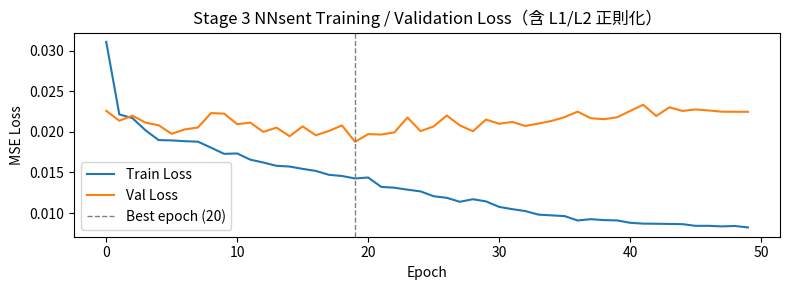

Stage 3 完成（NNword / NNmod 權重全程未被更新）


In [ ]:
import copy

model_sent = NNsent(hidden=64).to(device)
for p in model_word.parameters():
    p.requires_grad = False
for p in model_mod.parameters():
    p.requires_grad = False

# [新增 v7-3c] L1 / L2 正則化 —— 跟教授討論後，針對 14.5 觀察到的訓練/測試差距
# （尤其 Arousal）加上的過擬合對策：
#   L2：直接交給 Adam 的 weight_decay 處理（等於每步更新時額外對權重乘上一個
#       小於 1 的收縮係數，讓權重傾向變小，避免任何單一權重長得過大、對特定
#       訓練樣本過度敏感）。
#   L1：Adam 沒有內建 L1，改成訓練時手動把 L1_LAMBDA * sum(|w|) 加進 loss 一起
#       backward（只對 Linear 層的「權重矩陣」做 —— 用 p.dim() >= 2 篩選，
#       不含 bias、也不含 LayerNorm 的 scale/shift，這是常見慣例：對 bias 或
#       LayerNorm 做 L1 意義不大，還容易讓訓練變不穩定）。L1 會把不重要的權重
#       直接推向 0，等於間接做特徵/連結的篩選。
WEIGHT_DECAY = 1e-4   # L2 係數
L1_LAMBDA    = 1e-5   # L1 係數


def l1_penalty(model):
    l1 = 0.0
    for p in model.parameters():
        if p.dim() >= 2:
            l1 = l1 + p.abs().sum()
    return l1


opt_sent = optim.Adam(model_sent.parameters(), lr=1e-3, weight_decay=WEIGHT_DECAY)
sch_sent = optim.lr_scheduler.CosineAnnealingLR(opt_sent, T_max=50)


@torch.no_grad()
def eval_loss_sent(samples):
    """算一批樣本的平均 MSE（純預測誤差，不含 L1/L2 正則化項），拿來監控驗證集，
    才能跟訓練 loss 直接比較大小、看有沒有 overfitting。"""
    model_sent.eval()
    if not samples:
        return float('nan')
    total = 0.0
    for s in samples:
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        pv, pa, _ = model_sent(s['span_feats'])
        total += (0.5 * ((pv - y_v) ** 2 + (pa - y_a) ** 2).mean()).item()
    return total / len(samples)


print('=== Stage 3：訓練 NNsent（v7-3c：加入 L1/L2 正則化 + 驗證集監控 overfitting）===')
print(f'    L2 (weight_decay)={WEIGHT_DECAY}   L1_LAMBDA={L1_LAMBDA}')
print('    NNword + NNmod 全程凍結，只借用它們的 VA 輸出')
N_EPOCHS_SENT = 50
GRAD_ACCUM_SENT = 16
losses_s, losses_s_val = [], []
best_val, best_epoch, best_state = float('inf'), 0, None

for epoch in range(N_EPOCHS_SENT):
    model_sent.train()
    epoch_loss = 0.0
    idxs = np.random.permutation(len(cvas_train_samples))
    opt_sent.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s = cvas_train_samples[si]
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        pv, pa, _ = model_sent(s['span_feats'])
        loss_mse = 0.5 * ((pv - y_v) ** 2 + (pa - y_a) ** 2).mean()
        loss = loss_mse + L1_LAMBDA * l1_penalty(model_sent)   # 訓練用：MSE + L1 懲罰項
        (loss / GRAD_ACCUM_SENT).backward()
        epoch_loss += loss_mse.item()   # 記錄的是純 MSE，才能跟下面驗證集的數字直接比較
        if (step_i % GRAD_ACCUM_SENT == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_sent.parameters(), max_norm=1.0)
            opt_sent.step()
            opt_sent.zero_grad()
    sch_sent.step()
    losses_s.append(epoch_loss / len(idxs))

    val_loss = eval_loss_sent(cvas_val_samples)
    losses_s_val.append(val_loss)
    if val_loss < best_val:
        best_val, best_epoch = val_loss, epoch + 1
        best_state = copy.deepcopy(model_sent.state_dict())

    if (epoch + 1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_SENT} | Train Loss: {losses_s[-1]:.6f} | Val Loss: {val_loss:.6f}')

if best_state is not None:
    model_sent.load_state_dict(best_state)
    print(f'\n訓練結束，改用驗證損失最低的權重（第 {best_epoch} epoch，Val Loss={best_val:.6f}）'
          f'——避免直接拿訓練到最後一個 epoch、可能已經 overfit 的權重。')

plt.figure(figsize=(8, 3))
plt.plot(losses_s, label='Train Loss')
plt.plot(losses_s_val, label='Val Loss')
plt.axvline(best_epoch - 1, color='gray', linestyle='--', linewidth=1, label=f'Best epoch ({best_epoch})')
plt.title('Stage 3 NNsent Training / Validation Loss（含 L1/L2 正則化）')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend()
plt.tight_layout(); plt.show()

for p in model_word.parameters():
    p.requires_grad = True
for p in model_mod.parameters():
    p.requires_grad = True
print('Stage 3 完成（NNword / NNmod 權重全程未被更新）')

## 14.5 三階段完整評估（NNword / Pipeline / NNsent）

In [ ]:
@torch.no_grad()
def batch_predict_sent(samples):
    model_sent.eval()
    all_pv, all_pa = [], []
    for s in samples:
        pv, pa, _ = model_sent(s['span_feats'])
        all_pv.append(pv.item())
        all_pa.append(pa.item())
    return np.array(all_pv, dtype=np.float32), np.array(all_pa, dtype=np.float32)


pv_str, pa_str = batch_predict_sent(cvas_train_samples)
pv_sva, pa_sva = batch_predict_sent(cvas_val_samples)
pv_ste, pa_ste = batch_predict_sent(cvas_test_samples)

print('=' * 75)
print('【Stage 3：CVAS 句子層級評估】')
print('=' * 75)
print('\n[NNsent] CVAS 訓練集')
compute_metrics(pv_str, cvas_train_val, 'Valence')
compute_metrics(pa_str, cvas_train_aro, 'Arousal')
print('\n[NNsent] CVAS 驗證集（訓練時用來挑最佳 epoch，完全沒參與梯度更新）')
compute_metrics(pv_sva, cvas_val_val, 'Valence')
compute_metrics(pa_sva, cvas_val_aro, 'Arousal')
print('\n[NNsent] CVAS 測試集')
compute_metrics(pv_ste, cvas_test_val, 'Valence')
compute_metrics(pa_ste, cvas_test_aro, 'Arousal')

rows_cvas = [
    ('NNsent', '訓練', 'Valence', *metrics(pv_str, cvas_train_val)),
    ('NNsent', '訓練', 'Arousal', *metrics(pa_str, cvas_train_aro)),
    ('NNsent', '驗證', 'Valence', *metrics(pv_sva, cvas_val_val)),
    ('NNsent', '驗證', 'Arousal', *metrics(pa_sva, cvas_val_aro)),
    ('NNsent', '測試', 'Valence', *metrics(pv_ste, cvas_test_val)),
    ('NNsent', '測試', 'Arousal', *metrics(pa_ste, cvas_test_aro)),
]
summary_cvas = pd.DataFrame(
    rows_cvas,
    columns=['模型', '資料集', '維度', 'MAE', 'MSE', 'Pearson r', 'Kendall τ', 'Spearman ρ'],
)
summary_all = pd.concat([summary, summary_cvas], ignore_index=True)
print('\n三階段（NNword / Pipeline / NNsent）合併總表：')
print(summary_all.to_string(index=False))

# [新增 v7-3c] 過擬合診斷：直接比較訓練 / 驗證 / 測試三者的 Pearson r，
# 差距越大代表模型記住了訓練集裡的細節，卻沒有穩定推廣到沒看過的句子上
# ——這是跟教授開會後要求明確判斷 overfitting 的部分，數字可以直接放進論文。
_r_tr_v = metrics(pv_str, cvas_train_val)[2]
_r_va_v = metrics(pv_sva, cvas_val_val)[2]
_r_te_v = metrics(pv_ste, cvas_test_val)[2]
_r_tr_a = metrics(pa_str, cvas_train_aro)[2]
_r_va_a = metrics(pa_sva, cvas_val_aro)[2]
_r_te_a = metrics(pa_ste, cvas_test_aro)[2]
print('\n' + '=' * 75)
print('【過擬合診斷】Pearson r －訓練 / 驗證 / 測試')
print('=' * 75)
print(f'  Valence: {_r_tr_v:.4f} / {_r_va_v:.4f} / {_r_te_v:.4f}   訓練-驗證差距 = {_r_tr_v - _r_va_v:.4f}')
print(f'  Arousal: {_r_tr_a:.4f} / {_r_va_a:.4f} / {_r_te_a:.4f}   訓練-驗證差距 = {_r_tr_a - _r_va_a:.4f}')
print('  （差距越接近 0 代表泛化越好；驗證集在訓練過程中已經用來挑最佳 epoch，')
print('   測試集完全沒被用來做任何決定，是最終、只看一次的效能數字。）')

【Stage 3：CVAS 句子層級評估】

[NNsent] CVAS 訓練集
  Valence                        | MAE=0.0732  MSE=0.0088  r=0.8422  τ=0.6571  ρ=0.8345
  Arousal                        | MAE=0.1017  MSE=0.0161  r=0.6375  τ=0.4693  ρ=0.6436

[NNsent] CVAS 驗證集（訓練時用來挑最佳 epoch，完全沒參與梯度更新）
  Valence                        | MAE=0.0935  MSE=0.0161  r=0.7043  τ=0.5378  ρ=0.7020
  Arousal                        | MAE=0.1164  MSE=0.0215  r=0.4400  τ=0.3066  ρ=0.4406

[NNsent] CVAS 測試集
  Valence                        | MAE=0.0932  MSE=0.0148  r=0.7292  τ=0.5258  ρ=0.7082
  Arousal                        | MAE=0.1164  MSE=0.0216  r=0.3954  τ=0.2728  ρ=0.3928

三階段（NNword / Pipeline / NNsent）合併總表：
      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0168 0.0005     0.9952     0.9421      0.9935
  NNword  訓練 Arousal 0.0217 0.0008     0.9907     0.9269      0.9905
  NNword  測試 Valence 0.0759 0.0104     0.8666     0.6507      0.8355
  NNword  測試 Arousal 0.1116 0.0204     0.6221     0.4

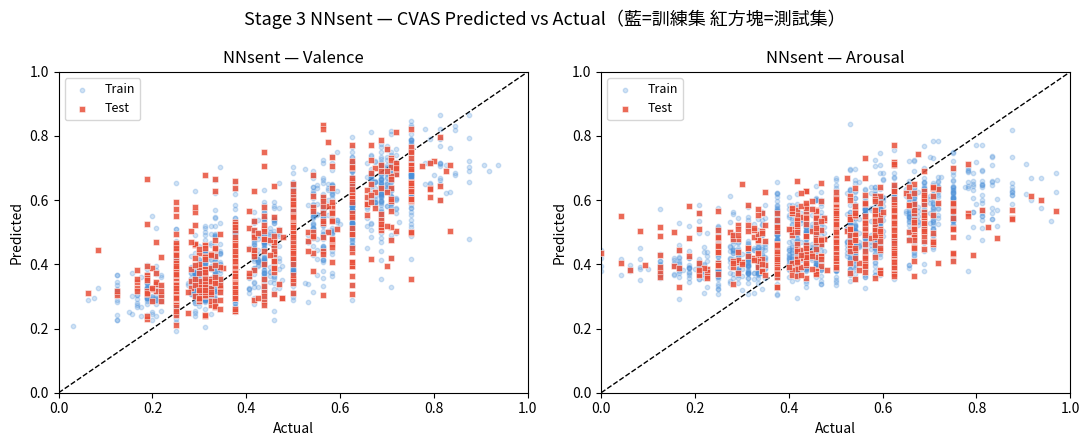

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle('Stage 3 NNsent — CVAS Predicted vs Actual（藍=訓練集 紅方塊=測試集）', fontsize=13)
configs_sent = [
    (axes[0], pv_str, cvas_train_val, pv_ste, cvas_test_val, 'NNsent — Valence'),
    (axes[1], pa_str, cvas_train_aro, pa_ste, cvas_test_aro, 'NNsent — Arousal'),
]
for ax, ptr, gtr, pte, gte, title in configs_sent:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color='#4A90D9', label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color='#E8503A', marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

## [新增] NNsent 預測 VA 分布散佈圖（仿論文 Fig. 3 樣式）

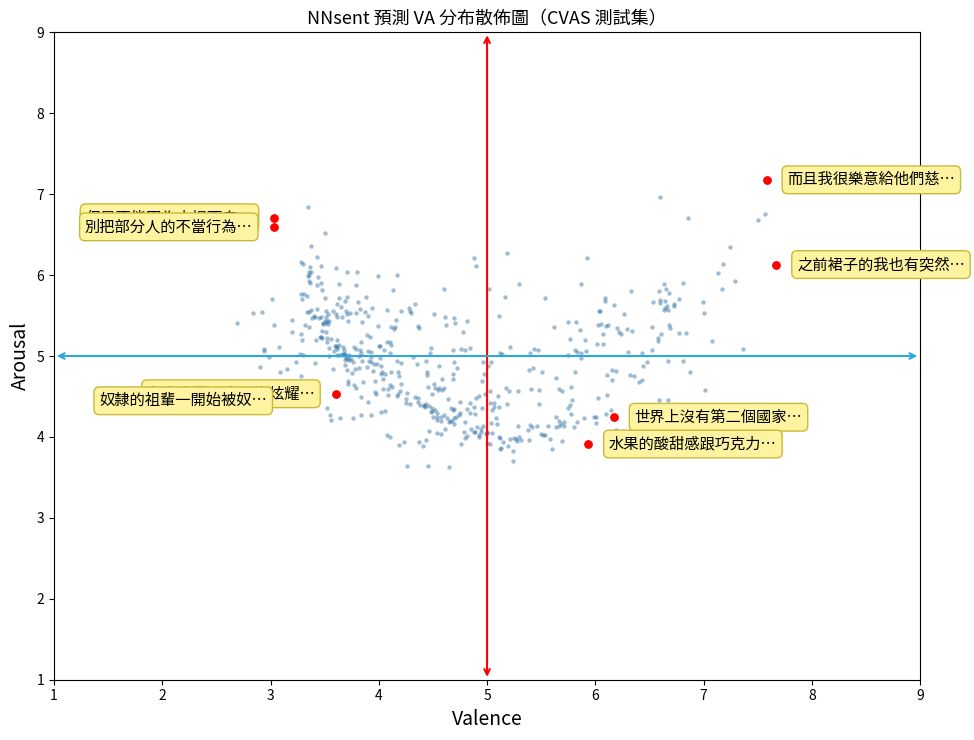

In [ ]:
# [新增] NNsent 預測 VA 分布散佈圖（仿論文 Fig. 3 樣式，畫測試集）
plot_va_scatter(pv_ste, pa_ste, [s['sentence'] for s in cvas_test_samples],
                'NNsent 預測 VA 分布散佈圖（CVAS 測試集）', savepath='nnsent_va_scatter.png')

## 14.6 哪些詞有幫助、哪些沒作用：Leave-One-Out 消融 + 每步貢獻度排行榜

作法：對每個句子，先用完整 span 序列跑一次 NNsent 得到「完整句子」的 VA；
再對每個 span 輪流「把它從依序的 span 序列中整個拿掉」（因為現在是遞迴鏈，
拿掉一個 span 後面所有步驟的狀態都會跟著改變，不能只是遮罩），重新跑一次
完整序列，比較兩次 VA 的差距 `ΔV / ΔA`。

這裡完全沒有重跑 BERT / NNword / NNmod —— 每個 span 的 VA、c_mod 早就在
14.4 算好存在 `sample['span_feats']` 裡了，Leave-One-Out 只是把某個位置
從 list 裡拿掉、重跑一次很小的 NNsent，所以對整個測試集做也很快。

In [ ]:
@torch.no_grad()
def _nnsent_forward_from_feats(span_feats):
    v, a, steps = model_sent(span_feats)
    return v.item(), a.item(), steps


@torch.no_grad()
def compute_span_importance(sample):
    """
    對一個 CVAS 樣本（含 span_feats/span_infos）計算每個 span 的：
      contrib_v/contrib_a — NNsent 該步驟對句子狀態的貢獻強度（0.5=沒影響，
                             偏離 0.5 越遠代表這一步影響句子情緒越大，
                             寫法跟 NNmod 的 c_mod 完全對應）
      delta_v/delta_a — Leave-One-Out：把這個 span 從序列中整個拿掉後，
                         整句最終 VA 的絕對變化量
      impact — sqrt(delta_v^2 + delta_a^2)，整合 V/A 兩軸的重要性分數
    """
    model_sent.eval()
    span_feats = sample['span_feats']
    span_infos = sample['span_infos']
    full_v, full_a, steps = _nnsent_forward_from_feats(span_feats)

    results = []
    for i in range(len(span_feats)):
        if len(span_feats) == 1:
            # 只有一個 span，拿掉後沒東西可跑 —— 視為退回中性值 0.5
            loo_v, loo_a = 0.5, 0.5
        else:
            loo_feats = span_feats[:i] + span_feats[i + 1:]
            loo_v, loo_a, _ = _nnsent_forward_from_feats(loo_feats)
        delta_v = full_v - loo_v
        delta_a = full_a - loo_a
        c_v, c_a = steps[i]
        results.append({
            'span_text': span_infos[i]['span_text'],
            'core_word': span_infos[i]['core_word'],
            'modifier': span_infos[i]['modifier'],
            'hit': span_infos[i]['hit'],
            'contrib_v': c_v,
            'contrib_a': c_a,
            'delta_v': float(delta_v),
            'delta_a': float(delta_a),
            'impact': float(np.sqrt(delta_v ** 2 + delta_a ** 2)),
        })
    return full_v, full_a, results


print('compute_span_importance 定義完成')

compute_span_importance 定義完成


### 全測試集彙整：資料驅動的「有幫助 / 普通 / 沒作用」門檻

In [ ]:
print('對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...')
all_span_rows = []
for s in cvas_test_samples:
    _, _, span_results = compute_span_importance(s)
    for r in span_results:
        r['sentence'] = s['sentence']
        all_span_rows.append(r)

span_df = pd.DataFrame(all_span_rows)
span_df['contrib'] = (span_df['contrib_v'] + span_df['contrib_a']) / 2
print(f'共分析 {len(span_df)} 個 span（來自 {len(cvas_test_samples)} 個測試句子）')

# 用整個測試集的 impact 分布切三分位，當作「有幫助 / 普通 / 沒作用」的資料驅動門檻
# （用分位數而不是寫死的絕對值，因為 impact 的尺度會隨資料集、模型調整）
q_low, q_high = span_df['impact'].quantile([0.33, 0.67])


def label_usefulness(impact):
    if impact >= q_high:
        return '有幫助'
    if impact <= q_low:
        return '沒作用'
    return '普通'


span_df['usefulness'] = span_df['impact'].apply(label_usefulness)
print(f'\nimpact 三分位門檻: 33%={q_low:.4f}  67%={q_high:.4f}')
print(span_df['usefulness'].value_counts())

對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...
共分析 684 個 span（來自 517 個測試句子）

impact 三分位門檻: 33%=0.0745  67%=0.1318
usefulness
普通     232
有幫助    226
沒作用    226
Name: count, dtype: int64


### 依「情感詞（核心詞）」與「修飾詞」分組的重要性排行榜

In [ ]:
print('=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===')
core_rank = (
    span_df[span_df['core_word'].notna()]
    .groupby('core_word')
    .agg(n=('impact', 'size'),
         mean_impact=('impact', 'mean'),
         mean_contrib=('contrib', 'mean'),
         mean_dV=('delta_v', 'mean'),
         mean_dA=('delta_a', 'mean'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print('\n【最有幫助的情感詞（平均 impact 最高，前 20）】')
print(core_rank.head(20).to_string())
print('\n【幾乎沒作用的情感詞（平均 impact 最低，前 20 —— 即使被抓進 pipeline 也不太影響整句 VA）】')
print(core_rank.tail(20).sort_values('mean_impact').to_string())

print('\n=== 依「修飾詞」分組：平均對整句 VA 的貢獻 ===')
mod_rank = (
    span_df[span_df['modifier'].notna()]
    .groupby('modifier')
    .agg(n=('impact', 'size'),
         mean_impact=('impact', 'mean'),
         mean_contrib=('contrib', 'mean'),
         mean_dV=('delta_v', 'mean'),
         mean_dA=('delta_a', 'mean'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print(mod_rank.to_string())

core_rank.to_csv('cvas_core_word_importance.csv', encoding='utf-8-sig')
mod_rank.to_csv('cvas_modifier_importance.csv', encoding='utf-8-sig')
span_df.to_csv('cvas_span_importance_raw.csv', index=False, encoding='utf-8-sig')
print('\n已輸出：cvas_core_word_importance.csv / cvas_modifier_importance.csv / cvas_span_importance_raw.csv')

=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===

【最有幫助的情感詞（平均 impact 最高，前 20）】
           n  mean_impact  mean_contrib   mean_dV   mean_dA
core_word                                                  
造謠         2     0.143698      0.449305 -0.137567  0.036117
黑暗         2     0.129886      0.415142 -0.078967 -0.066263
不如         2     0.111155      0.439582 -0.108448  0.007486
惡行         2     0.101073      0.481603 -0.053609  0.049714
壓迫         2     0.093177      0.398768 -0.091059 -0.006151
遵守         2     0.090218      0.489115 -0.004326 -0.031241
親          2     0.090057      0.642174  0.048096  0.071225
棒          3     0.088633      0.572160  0.007251  0.056949
誠          2     0.088584      0.527107  0.057930 -0.037472
怪          2     0.084273      0.452645 -0.081412 -0.002807
突然         2     0.082906      0.654001  0.065260  0.050240
進行         3     0.080458      0.465603  0.019578 -0.067718
擊          2     0.079330      0.576837  0.018029  0.072131
開放         2     0.078953      0.5

### 單句 Demo：逐 span 列出 contribution + LOO 貢獻 + 有幫助/沒作用 標籤

In [ ]:
@torch.no_grad()
def predict_sentence_with_importance(sentence, verbose=True):
    """
    句子推論 + 逐 span 重要性分析：
      contrib = 這一步對句子狀態的貢獻強度（0.5=沒影響，句內每一步各自獨立）
      DV/DA   = 把這個 span 從序列中整個拿掉後，整句 VA 的絕對變化量（LOO）
      impact  = sqrt(DV^2+DA^2)，用整個測試集算出的三分位數決定「有幫助/普通/沒作用」
    """
    model_word.eval(); model_mod.eval(); model_sent.eval()
    span_feats, span_infos, _ = build_span_feats_for_sentence(sentence)

    sample = {'span_feats': span_feats, 'span_infos': span_infos}
    full_v, full_a, span_results = compute_span_importance(sample)

    fv9 = round(full_v * 8 + 1, 3)
    fa9 = round(full_a * 8 + 1, 3)
    pol = '正向' if full_v > 0.625 else ('負向' if full_v < 0.375 else '中性')
    act = '高喚起' if full_a > 0.625 else ('低喚起' if full_a < 0.375 else '中喚起')

    if verbose:
        print(f'\n句子：「{sentence}」')
        print(f'整句 VA（1-9）→ Valence={fv9}  Arousal={fa9}  [{pol}/{act}]\n')
        print(f'{"span":16s} {"contrib":>9} {"DV":>8} {"DA":>8} {"impact":>8}  判斷')
        print('-' * 62)
        for r in sorted(span_results, key=lambda x: -x['impact']):
            tag = label_usefulness(r['impact'])
            contrib_disp = (r['contrib_v'] + r['contrib_a']) / 2
            print(f'{r["span_text"]:16s} {contrib_disp:9.3f} '
                  f'{r["delta_v"]:8.4f} {r["delta_a"]:8.4f} {r["impact"]:8.4f}  {tag}')
    return fv9, fa9, span_results


print('\n=== 句子推論 + 逐詞重要性 Demo ===')
for s in [
    '這次旅行真的非常開心，風景美極了！',
    '主治醫師強調血液透析，家屬却遲遲無法達到共識。',
    '視病如親，讓我十分的動容。',
    '雖然考試沒過，但心情還算平靜。',
    '非常憤怒，完全無法接受這種行為！',
]:
    predict_sentence_with_importance(s)


=== 句子推論 + 逐詞重要性 Demo ===

句子：「這次旅行真的非常開心，風景美極了！」
整句 VA（1-9）→ Valence=6.264  Arousal=5.511  [正向/中喚起]

span               contrib       DV       DA   impact  判斷
--------------------------------------------------------------
非常開心                 0.709   0.1579   0.0638   0.1704  有幫助

句子：「主治醫師強調血液透析，家屬却遲遲無法達到共識。」
整句 VA（1-9）→ Valence=5.234  Arousal=3.756  [中性/低喚起]

span               contrib       DV       DA   impact  判斷
--------------------------------------------------------------
無法                   0.396  -0.0557  -0.0410   0.0692  沒作用
達到                   0.493   0.0308  -0.0154   0.0345  沒作用
強                    0.514   0.0120  -0.0047   0.0129  沒作用

句子：「視病如親，讓我十分的動容。」
整句 VA（1-9）→ Valence=6.362  Arousal=5.08  [正向/中喚起]

span               contrib       DV       DA   impact  判斷
--------------------------------------------------------------
親                    0.673   0.1703   0.0100   0.1706  有幫助

句子：「雖然考試沒過，但心情還算平靜。」
整句 VA（1-9）→ Valence=6.873  Arousal=4.386  [正向/中喚起]

span        